# Notebook 02: content perturbation — focused dependent-block follow-up

<div style="border-left:4px solid #2563eb; padding:10px 14px; background:#eff6ff; color:#173e75;">
<strong>NEW DEFAULT: investigate the dependent-block discrepancy.</strong><br>
Run All now skips the original four-setting table and independent strength sweep,
then runs the focused study near the end. New changes are marked CHANGED [7] or ADDED [8–11].
</div>

The original four-setting experiment and its diagnostics are retained. To rerun it,
set `RUN_MAIN_TABLE=True`; to rerun its independent strength sweep, set
`RUN_ORIGINAL_STRENGTH_SWEEP=True` in the experiment settings cell.

**Focused defaults:** case 3 (`dependent_blocks`), fixed world/mixing seed 0,
training seed 0, five encoder outputs, batch/negative-pool size 1,024,
content perturbation strengths $\sigma_c=0$ and $0.1$, and checkpoints at
10,000, 30,000 and 60,000 updates. This requires **two training trajectories**,
not six separate trainings. Repeating worlds or training seeds is optional.

**What the focused study records:** original content/style recovery, recovery of the
same unit-variance content directions at every budget, an oracle probe reference,
held-out contrastive loss, and output scale/covariance diagnostics. Trained models,
optimizer and random-generator states, and held-out representations are saved so
training can resume and probes can be revisited without retraining.

**Why world 0 first:** under the correlated linear benchmark, all five content
directions are selected both before and after the default content perturbation.
This avoids changing the benchmark's selected subspace during the initial comparison.
One fixed world and initialization form a diagnostic study, not a three-seed
reproduction of the paper's reported average.

**Sampling correspondence checked:** the released `main_mlp.py` independently draws
original observations as negatives, just as this notebook does. It also uses Wishart
covariances in its dependent settings. The focused study does not change either rule.
Reference: https://github.com/ysharma1126/ssl_identifiability/blob/master/main_mlp.py

**Output status:** the added training cells require execution in your PyTorch/GPU
environment. The earlier supplied outputs remain labelled as historical results.
For Colab, set the result directory to persistent storage if you want checkpoints to
survive a disconnected or replaced runtime.

## Part A: shared setup (identical in every notebook)

The cells of this part define the paper's simulation: the latent world, the augmentation at the latent level, the frozen mixing network, the encoder and the contrastive objective. They are copied verbatim from notebook 00, where each step is explained. Run them first; Part B uses `cfg`, `device`, `Settings`, `make_world`, `make_mixing`, `make_encoder` and `contrastive_loss` from here. The demonstration setting is `independent_partial`; each experiment overrides what it changes through `replace(cfg, ...)`.


## 2. Setup and settings

Use a Python 3.10+ notebook kernel. If an import is missing, uncomment the installation line, run it, and restart the kernel if requested. PyTorch can use an available NVIDIA GPU or Apple Silicon GPU; CPU also works. Numerical results can differ across devices and software versions.

In [1]:
import copy
import math
import platform
import time
from dataclasses import dataclass, asdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy.stats import wishart
import sklearn
from sklearn.linear_model import LinearRegression
from sklearn.kernel_ridge import KernelRidge
from sklearn.metrics import r2_score
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

import torch
from torch import nn
from IPython.display import display

%matplotlib inline
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelsize": 11, "axes.titlesize": 12, "font.size": 10,
})

versions = {
    "Python": platform.python_version(), "PyTorch": torch.__version__,
    "NumPy": np.__version__, "SciPy": scipy.__version__,
    "scikit-learn": sklearn.__version__,
}
display(pd.Series(versions, name="Version").to_frame())

,Version
Python,3.13.15
PyTorch,2.11.0+cu130
NumPy,2.1.3
SciPy,1.16.3
scikit-learn,1.6.1


The four named scenarios correspond to the progression in §5.1. Start with `independent_partial`, then change one setting at a time and rerun from this cell.

| Scenario | Chance each style coordinate changes | Dependence within blocks | Style depends on content |
|---|---:|---|---|
| `independent_all` | 1.00 | No | No |
| `independent_partial` | 0.75 | No | No |
| `dependent_blocks` | 0.75 | Yes | No |
| `content_causes_style` | 0.75 | Yes | Yes |

`content_dim` and `style_dim` describe the simulated world. `representation_dim` describes the encoder's output. The standard setting makes the output dimension equal to the content dimension.

`steps` is the number of parameter updates. Every update uses fresh simulated data. `batch_size` controls both the number of positive pairs and the size of the independent negative pool. Each anchor is compared with every item in that pool.

In [2]:
SCENARIO = "independent_partial"

SCENARIOS = {
    "independent_all":      (1.00, False, False),
    "independent_partial":  (0.75, False, False),
    "dependent_blocks":     (0.75, True,  False),
    "content_causes_style": (0.75, True,  True),
}

@dataclass
class Settings:
    seed: int = 7                          # Controls randomness so a run can be repeated.
    content_dim: int = 5                   # Number of true content variables, unchanged across paired views.
    style_dim: int = 5                     # Number of true style variables, which may change across views.
    representation_dim: int = 5            # Number of encoder outputs; equals content_dim.
    style_change_prob: float = 0.75        # Probability that each style coordinate is selected for change ("Biased Coin")
    statistical_dependence: bool = False   # If True, allow correlations within content, style noise, and augmentation noise.
    content_dependent_style: bool = False  # If True, generate style as s = a + Bc + noise.
    marginal_std: float = 1.0              # Standard deviation of content and residual style noise when dependence is off.
    style_noise_std: float = 1.0           # Standard deviation of noise added to selected style coordinates when dependence is off.
    mixing_layers: int = 3                 # Number of linear layers in the fixed latent-to-observation network.
    condition_pool: int = 25000            # Number of random matrices used to estimate a conditioning threshold.
    condition_quantile: float = 0.001      # Set the threshold using roughly the best-conditioned 0.1% of those matrices.
    learning_rate: float = 1e-4            # Controls the size of the encoder's parameter updates during training.
    temperature: float = 1.0               # Scales distances in the contrastive loss; smaller values sharpen comparisons.
    batch_size: int = 1024                  # Positive pairs per update; also the number of independent negative examples.
    steps: int = 10000                      # Total number of encoder parameter updates.
    log_every: int = 200                   # Print training progress every this many updates.
    probe_train_size: int = 3000            # Examples used to fit evaluation models that predict latents from representations.
    probe_test_size: int = 5000            # Separate examples used to test those evaluation models.
    device: str = "auto"                   # Automatically choose CUDA, then MPS, then CPU; can also set one explicitly.

cfg = Settings()
(cfg.style_change_prob, cfg.statistical_dependence,
 cfg.content_dependent_style) = SCENARIOS[SCENARIO]

# Original script's training scale (not enabled for this demonstration):
# cfg.batch_size = 6144
# cfg.steps = 100001
# The original nonlinear evaluation fits probes on 5 * 4096 examples and
# evaluates on 10 fresh batches of 4096. Kernel regression at that size is costly.

assert min(cfg.content_dim, cfg.style_dim, cfg.representation_dim) >= 1
assert 0 <= cfg.style_change_prob <= 1
assert min(cfg.marginal_std, cfg.style_noise_std, cfg.temperature) > 0
assert cfg.steps > 0 and cfg.batch_size > 1

if cfg.device != "auto":
    device = torch.device(cfg.device)
elif torch.cuda.is_available():
    device = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

torch.manual_seed(cfg.seed)
torch.set_num_threads(2)  # Avoid oversubscribing CPU cores in small examples.
latent_dim = cfg.content_dim + cfg.style_dim
print(f"Scenario: {SCENARIO}; device: {device}")
display(pd.Series(asdict(cfg), name="Setting").to_frame())

Scenario: independent_partial; device: cuda


,Setting
seed,7
content_dim,5
style_dim,5
representation_dim,5
style_change_prob,0.75
statistical_dependence,False
content_dependent_style,False
marginal_std,1.0
style_noise_std,1.0
mixing_layers,3


## 3. Build the latent world

We first draw content, then draw style:
$
c\sim N(0,\Sigma_c),\qquad
s=a+Bc+\varepsilon_s,\qquad
\varepsilon_s\sim N(0,\Sigma_s),
$
with independent content and residual draws.

If `statistical_dependence=False`, the covariance matrices are diagonal. If it is `True`, we generate covariance matrices that allow coordinates within each block to be correlated. A Wishart draw is simply a convenient way to generate a positive definite covariance matrix.

If `content_dependent_style=False`, we set $(a=0)$ and $(B=0)$. Otherwise, $(a+Bc)$ makes the distribution of style depend on content. This implements the paper's example of content influencing style.

The covariance matrices and $(a,B)$ are drawn once and then kept fixed. We repeatedly sample new people or objects from this same artificial world.

In [3]:
def make_world(settings):
    """Create fixed parameters of the data distribution on the CPU."""
    rng = np.random.default_rng(settings.seed)
    nc, ns = settings.content_dim, settings.style_dim

    def covariance(dim, std):
        if settings.statistical_dependence:
            # Match the intended Wishart construction in the original experiment.
            matrix = np.atleast_2d(wishart.rvs(df=dim, scale=np.eye(dim), random_state=rng))
        else:
            matrix = (std ** 2) * np.eye(dim)
        return torch.tensor(matrix, dtype=torch.float64)

    Sigma_c = covariance(nc, settings.marginal_std)
    Sigma_s = covariance(ns, settings.marginal_std)
    Sigma_aug = covariance(ns, settings.style_noise_std)
    # As in upstream spaces.py, explicit covariances supersede the std arguments.
    a = torch.zeros(ns)
    B = torch.zeros(ns, nc)
    if settings.content_dependent_style:
        a = torch.tensor(rng.standard_normal(ns), dtype=torch.float32)
        B = torch.tensor(rng.standard_normal((ns, nc)), dtype=torch.float32)
    return {
        "L_c": torch.linalg.cholesky(Sigma_c).float(),
        "L_s": torch.linalg.cholesky(Sigma_s).float(),
        "L_aug": torch.linalg.cholesky(Sigma_aug).float(),
        "a": a, "B": B,
    }

world = make_world(cfg)

def sample_latents(size, generator):
    """Draw z=(c,s). Latent values are used by the simulator and evaluator."""
    c = torch.randn(size, cfg.content_dim, generator=generator) @ world["L_c"].T
    eps_s = torch.randn(size, cfg.style_dim, generator=generator) @ world["L_s"].T
    s = world["a"] + c @ world["B"].T + eps_s
    return torch.cat([c, s], dim=1)

display(pd.DataFrame({
    "block": ["content", "style residual", "augmentation noise"],
    "dimension": [cfg.content_dim, cfg.style_dim, cfg.style_dim],
    "covariance": ["L_c @ L_c.T", "L_s @ L_s.T", "L_aug @ L_aug.T"],
}))

,block,dimension,covariance
0,content,5,L_c @ L_c.T
1,style residual,5,L_s @ L_s.T
2,augmentation noise,5,L_aug @ L_aug.T


For each original example, choose which style coordinates change using independent Bernoulli draws:
$
M_j\sim\mathrm{Bernoulli}(p),\qquad
\widetilde s=s+M\odot\eta,\qquad
\eta\sim N(0,\Sigma_{\mathrm{aug}}).
$
The symbol $(\odot)$ means coordinatewise multiplication. Content is copied exactly. A style coordinate whose mask equals zero is also copied exactly. The selected subset \(A\) is the set of coordinates whose masks equal one.

We additionally generate independent examples for the negative pool. They come from the same original latent distribution; they are not paired with the anchors.

When $(p>0)$ and the noise covariance is positive definite, each style coordinate has a chance to vary locally. Setting $(p=0)$ removes this property and changes the identification problem.

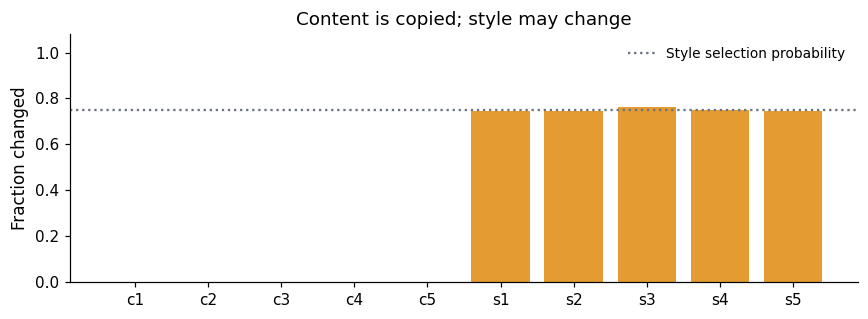

In [4]:
def augment_latents(z, generator):
    nc = cfg.content_dim
    style = z[:, nc:]
    mask = (torch.rand(style.shape, generator=generator) < cfg.style_change_prob)
    noise = torch.randn(style.shape, generator=generator) @ world["L_aug"].T
    changed_style = style + mask * noise
    return torch.cat([z[:, :nc], changed_style], dim=1)

def sample_triplet(size, generator):
    z = sample_latents(size, generator)
    z_negative = sample_latents(size, generator)
    z_augmented = augment_latents(z, generator)
    return z, z_augmented, z_negative

# A separate random stream keeps this inspection from changing training data.
inspection_rng = torch.Generator().manual_seed(cfg.seed + 10)
z_check, z_aug_check, _ = sample_triplet(5000, inspection_rng)
assert torch.equal(z_check[:, :cfg.content_dim], z_aug_check[:, :cfg.content_dim])
change_rates = (z_check != z_aug_check).float().mean(dim=0).numpy()
names = ([f"c{i+1}" for i in range(cfg.content_dim)] +
         [f"s{i+1}" for i in range(cfg.style_dim)])

fig, ax = plt.subplots(figsize=(8, 3))
colors = ["#227c9d"] * cfg.content_dim + ["#e49b32"] * cfg.style_dim
ax.bar(names, change_rates, color=colors)
ax.axhline(cfg.style_change_prob, color="#6b7280", linestyle=":", label="Style selection probability")
ax.set(ylim=(0, 1.08), ylabel="Fraction changed", title="Content is copied; style may change")
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

## 4. Hide the latents behind a fixed mixing network

The mixing network converts $(z)$ into $(x)$. It has square, invertible weight matrices and LeakyReLU activations with a nonzero negative slope. Its input and output both have dimension $(n_c+n_s)$, as in this particular synthetic experiment.

The condition number measures how unevenly a matrix stretches different directions. The code samples candidate matrices and keeps well-conditioned ones. This reduces severe numerical distortion; it is not a training step.

The mixing parameters are frozen. Only the encoder will be trained. LeakyReLU is invertible here but has a kink at zero, so this implementation is not literally smooth everywhere as required by the theorems.

In [5]:
def make_mixing(settings):
    """Adapt the upstream well-conditioned, square mixing MLP."""
    n = settings.content_dim + settings.style_dim
    rng = np.random.default_rng(settings.seed + 100)

    def candidate():
        matrix = rng.uniform(-1, 1, size=(n, n))
        return matrix / np.linalg.norm(matrix, axis=0, keepdims=True)

    conditions = np.array([
        np.linalg.cond(candidate()) for _ in range(settings.condition_pool)
    ])
    threshold = np.sort(conditions)[int(settings.condition_pool * settings.condition_quantile)]
    modules, accepted_conditions = [], []
    for layer in range(settings.mixing_layers):
        matrix = candidate()
        while np.linalg.cond(matrix) > threshold:
            matrix = candidate()
        linear = nn.Linear(n, n, bias=False)
        with torch.no_grad():
            linear.weight.copy_(torch.tensor(matrix, dtype=torch.float32))
        modules.append(linear)
        accepted_conditions.append(np.linalg.cond(matrix))
        if layer < settings.mixing_layers - 1:
            modules.append(nn.LeakyReLU(negative_slope=0.2))
    network = nn.Sequential(*modules).to(device)
    network.requires_grad_(False)
    network.eval()
    return network, accepted_conditions

mixing, condition_numbers = make_mixing(cfg)
print("Mixing layer condition numbers:", np.round(condition_numbers, 2))
print("Mixing parameters trainable:", any(p.requires_grad for p in mixing.parameters()))

with torch.no_grad():
    x_check = mixing(z_check[:5].to(device))
print("Latent shape:", tuple(z_check[:5].shape))
print("Observation shape:", tuple(x_check.shape))

Mixing layer condition numbers: [4.56 4.26 4.91]
Mixing parameters trainable: False
Latent shape: (5, 10)
Observation shape: (5, 10)


The encoder receives the mixed observation and outputs \(k\) numbers, where `representation_dim = k`. We preserve the original script's hidden-layer widths and activations.

With the default dimensions, the learned mapping is $(g:\mathbb R^{10}\to\mathbb R^5)$. It cannot invert the full observation. The desired result is an invertible representation of the five-dimensional content block after discarding additional style variation.

In [6]:
def make_encoder(settings):
    n = settings.content_dim + settings.style_dim
    # Same hidden widths as main_mlp.py; final layer has no activation.
    widths = [n, n * 10, n * 50, n * 50, n * 50, n * 50, n * 10,
              settings.representation_dim]
    modules = []
    for i, (n_in, n_out) in enumerate(zip(widths[:-1], widths[1:])):
        modules.append(nn.Linear(n_in, n_out))
        if i < len(widths) - 2:
            modules.append(nn.LeakyReLU(negative_slope=0.01))
    return nn.Sequential(*modules).to(device)

torch.manual_seed(cfg.seed + 200)
encoder = make_encoder(cfg)
initial_encoder = copy.deepcopy(encoder).eval()
print(encoder)
print("Trainable encoder parameters:", sum(p.numel() for p in encoder.parameters()))

Sequential(
  (0): Linear(in_features=10, out_features=100, bias=True)
  (1): LeakyReLU(negative_slope=0.01)
  (2): Linear(in_features=100, out_features=500, bias=True)
  (3): LeakyReLU(negative_slope=0.01)
  (4): Linear(in_features=500, out_features=500, bias=True)
  (5): LeakyReLU(negative_slope=0.01)
  (6): Linear(in_features=500, out_features=500, bias=True)
  (7): LeakyReLU(negative_slope=0.01)
  (8): Linear(in_features=500, out_features=500, bias=True)
  (9): LeakyReLU(negative_slope=0.01)
  (10): Linear(in_features=500, out_features=100, bias=True)
  (11): LeakyReLU(negative_slope=0.01)
  (12): Linear(in_features=100, out_features=5, bias=True)
)
Trainable encoder parameters: 853705


## 5. The contrastive objective

Let $(u_i=g(x_i))$, $(v_i=g(\widetilde x_i))$, and $(w_j=g(x_j^-))$. The first two form a positive pair. The $(w_j)$'s are encoded observations from the independent negative pool.

For the original loss's default settings, define
$
d_i^+=\|u_i-v_i\|^2,\qquad d_{ij}^-=\|u_i-w_j\|^2.
$
With batch size $(m)$ and temperature $(\tau)$, the loss is
$
\frac1m\sum_i\left[
\frac{d_i^+}{\tau}
+\log\left\{\frac{e^{-d_i^+/\tau}+\sum_{j=1}^m e^{-d_{ij}^-/\tau}}{m+1}\right\}
\right].
$

The first term encourages paired representations to agree. The second makes mapping everything to the same point unattractive: independent examples can instead be separated while positive pairs remain close. Both effects depend on the same learned representation.

This is the squared-distance, InfoNCE-style objective used in the synthetic script. The denominator uses a mean rather than a sum, changing the loss by a constant for fixed batch size. Negative loss values are therefore normal.

We do not calculate differential entropy directly. Theorem 4.4 studies exact population alignment plus entropy on a bounded output domain; this code uses a finite batch contrastive surrogate and unconstrained outputs. Its numerical behavior is evidence about the method, not a direct execution of that theorem's assumptions.

In [7]:
def contrastive_loss(anchor, positive, negative, temperature=1.0):
    """Same objective as LpSimCLRLoss at its default p=2, alpha=0.5."""
    positive_distance = (anchor - positive).square().sum(dim=1)
    # Algebraically equal to all pairwise squared differences, using less memory.
    negative_distance = (
        anchor.square().sum(dim=1, keepdim=True)
        + negative.square().sum(dim=1).unsqueeze(0)
        - 2 * anchor @ negative.T
    ).clamp_min(0)
    all_distances = torch.cat([negative_distance, positive_distance[:, None]], dim=1)
    alignment = positive_distance / temperature
    contrast = torch.logsumexp(-all_distances / temperature, dim=1)
    contrast = contrast - math.log(all_distances.shape[1])
    loss = (alignment + contrast).mean()
    return loss, alignment.mean().detach(), contrast.mean().detach()

zero = torch.zeros(8, cfg.representation_dim, device=device)
collapsed_loss, _, _ = contrastive_loss(zero, zero, zero, cfg.temperature)
print(f"Loss of a constant representation: {collapsed_loss.item():.3f}")

Loss of a constant representation: 0.000


## Part B: Experiment 2


## Experiment 2: paired invariant and perturbed content

The question is how recovery changes when the originally designated content factors
also vary across views. We compare $\sigma_c=0$ with $\sigma_c=0.1$ for the same world,
mixing network, encoder initialization, training random draws, and probe observations.

The sampler **always** draws the content mask and perturbation, even when
$\sigma_c=0$. Keeping these draws prevents a change in perturbation strength from
changing subsequent training observations. The original content perturbation remains
independent across coordinates; we do not change its covariance to match the content
covariance. Style is perturbed from the already sampled style value, without regenerating
style from the perturbed content.

The price diagnostics use the actual covariance matrices. In dependent settings,
Wishart draws need not have unit diagonal, and causal style variation also includes
variation inherited from content. Coordinate prices alone therefore need not identify
the cheapest linear information. The covariance diagnostics below provide a reference
from the generalized linear Gaussian, fixed-output-variance benchmark. They are not
a recovery guarantee for the finite InfoNCE runs.

The strength sweep remains restricted to the independent setting and seed 0.
At its default endpoint $\sigma_c=1$, content and style prices tie; this is an intentional
comparison, not a setting in which content is strictly cheaper.

In [11]:
# CHANGED [1, 5]: paired controls and versioned, configuration-aware cache.
import hashlib
import json
from dataclasses import asdict, replace
from scipy.linalg import eigh

# CHANGED [7]: default Run All now launches only the focused study added below.
RUN_MAIN_TABLE = False                 # True restores the original four-setting comparison
RUN_ORIGINAL_STRENGTH_SWEEP = False    # True restores the original independent sweep

CONTENT_SIGMA = 0.10
CONTENT_CHANGE_PROB = 1.0
SEEDS = [0, 1, 2]
STEPS = cfg.steps
COMPETITION_SIGMAS = [0.0, 0.1, 0.3, 0.6, 1.0]  # independent_all, seed 0 only; [] skips
PRICE_SAMPLES = 50000
EXPERIMENT_VERSION = 'exp2_paired_v2'  # bump this after changing the sampling/training code
EXT2_DIR = Path('extension_perturbed_content_v2')
EXT2_DIR.mkdir(parents=True, exist_ok=True)

ROWS = [
    ('independent_all',      1.00, False, False),
    ('independent_partial',  0.75, False, False),
    ('dependent_blocks',     0.75, True,  False),
    ('content_causes_style', 0.75, True,  True),
]
PAPER = {
    'independent_all':      (1.00, 0.00, 0.07, 0.00),
    'independent_partial':  (1.00, 0.00, 0.06, 0.05),
    'dependent_blocks':     (0.98, 0.03, 0.37, 0.05),
    'content_causes_style': (0.99, 0.01, 0.80, 0.08),
}
NC, NS = cfg.content_dim, cfg.style_dim
N = NC + NS
COORDS = [f'c{i+1}' for i in range(NC)] + [f's{i+1}' for i in range(NS)]
MAIN_SIGMAS = [0.0, CONTENT_SIGMA]
KRR_GRID = {'kernelridge__alpha': [1.0, 0.1, 0.01, 0.001],
            'kernelridge__gamma': [float(g) for g in np.logspace(-2, 2, 4)]}

assert CONTENT_SIGMA > 0 and 0 < CONTENT_CHANGE_PROB <= 1
assert len(SEEDS) == len(set(SEEDS)) and len(SEEDS) > 0
assert STEPS > 0 and PRICE_SAMPLES > 1
assert all(s >= 0 for s in COMPETITION_SIGMAS)
print(f'Original paired table enabled: {RUN_MAIN_TABLE}; device: {device}.')
print('Original independent sweep enabled:', RUN_ORIGINAL_STRENGTH_SWEEP)


def draw_z(settings, w, size, gen):
    c = torch.randn(size, settings.content_dim, generator=gen) @ w["L_c"].T
    eps = torch.randn(size, settings.style_dim, generator=gen) @ w["L_s"].T
    return torch.cat([c, w["a"] + c @ w["B"].T + eps], dim=1)


def content_std(w):
    """Marginal std of each content coordinate: sqrt(diag(L_c L_c^T))."""
    return torch.sqrt((w["L_c"] ** 2).sum(dim=1))


def draw_leaky_triplet(settings, w, size, gen, sigma_c, p_c):
    """(z, z~, z_negative) where style is nudged as in the paper AND content is nudged too.

    Content nudge: with probability p_c per coordinate, add N(0, (sigma_c * std_l)^2),
    i.e. a nudge of sigma_c times the coordinate's natural spread. Each coordinate price is then
    pi_c = p_c * sigma_c^2 in every scenario. Direction prices can differ under correlation.
    """
    z = draw_z(settings, w, size, gen)
    # VERIFIED: the released main_mlp.py also draws negatives from the original marginal.
    z_neg = draw_z(settings, w, size, gen)
    c, s = z[:, :settings.content_dim], z[:, settings.content_dim:]
    mask_s = torch.rand(s.shape, generator=gen) < settings.style_change_prob
    noise_s = torch.randn(s.shape, generator=gen) @ w["L_aug"].T
    # CHANGED [1]: keep these draws unconditional, including when sigma_c == 0.
    # This matches the random training draws across invariant/perturbed controls.
    mask_c = torch.rand(c.shape, generator=gen) < p_c
    noise_c = torch.randn(c.shape, generator=gen) * (sigma_c * content_std(w))
    z_aug = torch.cat([c + mask_c * noise_c, s + mask_s * noise_s], dim=1)
    return z, z_aug, z_neg


def empirical_prices(settings, w, sigma_c, p_c, n=50000):
    """r_l = Var(z_l~ - z_l) / Var(z_l) estimated from n pairs, for every coordinate."""
    z, z_aug, _ = draw_leaky_triplet(settings, w, n, torch.Generator().manual_seed(12345), sigma_c, p_c)
    return ((z_aug - z).var(dim=0) / z.var(dim=0)).numpy()

Original paired table enabled: False; device: cuda.
Original independent sweep enabled: False


### <span style="color:#2563eb">ADDED: prices for every seed and direction diagnostics</span>

For correlated Gaussian latents, the price of a linear quantity $q=\alpha^\top z$ is
$\alpha^\top D\alpha/(\alpha^\top\Sigma_z\alpha)$.
The reference directions solve $D\alpha=\lambda\Sigma_z\alpha$.
For causal worlds, use the **full joint covariance**; separate content/style ranges
cannot be combined into a selection rule. These are linear-benchmark diagnostics,
not a claim that InfoNCE must learn the reference directions.

In [12]:
# ADDED [3, 4]: exact coordinate prices and full covariance-based direction prices.
# These functions use NumPy/SciPy and do not require training a model.
def covariance_diagnostics(Sigma_c, Sigma_residual, Sigma_aug, B,
                           p_style, sigma_c, p_content):
    Sigma_c = np.asarray(Sigma_c, dtype=np.float64)
    Sigma_residual = np.asarray(Sigma_residual, dtype=np.float64)
    Sigma_aug = np.asarray(Sigma_aug, dtype=np.float64)
    B = np.asarray(B, dtype=np.float64)
    nc, ns = len(Sigma_c), len(Sigma_residual)
    Sigma_style = Sigma_residual + B @ Sigma_c @ B.T
    Sigma_z = np.block([[Sigma_c, Sigma_c @ B.T],
                        [B @ Sigma_c, Sigma_style]])
    # The content sampler uses independent coordinatewise changes, even for correlated c.
    D_content = p_content * sigma_c**2 * np.diag(np.diag(Sigma_c))
    # Independent masks give factor p on diagonal entries and p^2 off the diagonal.
    D_style = (p_style**2 * Sigma_aug
               + p_style * (1 - p_style) * np.diag(np.diag(Sigma_aug)))
    D = np.block([[D_content, np.zeros((nc, ns))],
                  [np.zeros((ns, nc)), D_style]])
    coordinate_prices = np.diag(D) / np.diag(Sigma_z)
    return Sigma_z, D, coordinate_prices, D_content, D_style


def linear_price_directions(Sigma_z, D):
    """Columns alpha[:, k] define unit-population-variance quantities z @ alpha[:, k]."""
    Sigma_z = (np.asarray(Sigma_z) + np.asarray(Sigma_z).T) / 2
    D = (np.asarray(D) + np.asarray(D).T) / 2
    prices, alpha = eigh(D, Sigma_z)
    tolerance = 1e-10 * max(1.0, np.max(np.abs(prices)))
    if prices.min() < -tolerance:
        raise ValueError('A materially negative direction price indicates invalid covariances.')
    return np.maximum(prices, 0.0), alpha


def benchmark_coordinate_r2(Sigma_z, alpha, rep_dim):
    """Ideal coordinate recovery from the lowest-price linear subspace, not a fitted probe."""
    cross = Sigma_z @ alpha[:, :rep_dim]
    return np.clip(np.sum(cross**2, axis=1) / np.diag(Sigma_z), 0.0, 1.0)


def world_parameters_numpy(w):
    # Use the actual float32 Cholesky factors used by the sampler, not nominal std settings.
    arrays = {k: v.detach().cpu().numpy().astype(np.float64) for k, v in w.items()}
    return arrays


def world_diagnostics(settings, w, sigma_c, p_c):
    arrays = world_parameters_numpy(w)
    Sc = arrays['L_c'] @ arrays['L_c'].T
    Sr = arrays['L_s'] @ arrays['L_s'].T
    Sa = arrays['L_aug'] @ arrays['L_aug'].T
    Sigma_z, D, prices, Dc, Ds = covariance_diagnostics(
        Sc, Sr, Sa, arrays['B'], settings.style_change_prob, sigma_c, p_c)
    eigenprices, alpha = linear_price_directions(Sigma_z, D)
    content_prices, _ = linear_price_directions(Sc, Dc)
    style_prices, _ = linear_price_directions(Sigma_z[NC:, NC:], Ds)
    d = settings.representation_dim
    gap = float(eigenprices[d] - eigenprices[d-1]) if d < N else None
    strict = d == N or gap > (1e-8 + 1e-6 * max(abs(eigenprices[d-1]), abs(eigenprices[d])))
    # At a cutoff tie, report no unique coordinate prediction: many subspaces can be optimal.
    ideal = benchmark_coordinate_r2(Sigma_z, alpha, d) if strict else None
    return {'Sigma_z': Sigma_z, 'D': D, 'coordinate_prices': prices,
            'direction_prices': eigenprices, 'alpha': alpha,
            'content_direction_prices': content_prices,
            'style_direction_prices': style_prices,
            'cutoff_gap': gap, 'strict_cutoff': bool(strict), 'ideal_coordinate_r2': ideal}


def settings_for(scenario, p_change, statistical, causal, sigma_c, seed):
    return replace(cfg, seed=seed, style_change_prob=p_change,
                   statistical_dependence=statistical, content_dependent_style=causal,
                   representation_dim=NC, steps=STEPS)


# ADDED [3]: display every seed before training, so a seed-zero table cannot hide price reversals.
preflight_rows, direction_reference_rows = [], []
for scenario, p_change, statistical, causal in ROWS:
    for seed in SEEDS:
        for sigma_c in MAIN_SIGMAS:
            settings = settings_for(scenario, p_change, statistical, causal, sigma_c, seed)
            diag = world_diagnostics(settings, make_world(settings), sigma_c, CONTENT_CHANGE_PROB)
            base = {'scenario': scenario, 'seed': seed, 'sigma_c': sigma_c}
            preflight_rows.append({**base, **dict(zip(COORDS, diag['coordinate_prices']))})
            direction_reference_rows.append({
                **base,
                'content_direction_min': float(diag['content_direction_prices'].min()),
                'content_direction_max': float(diag['content_direction_prices'].max()),
                'style_only_direction_min': float(diag['style_direction_prices'].min()),
                'cutoff_price': float(diag['direction_prices'][NC-1]),
                'next_price': float(diag['direction_prices'][NC]),
                'cutoff_gap': diag['cutoff_gap'], 'strict_cutoff': diag['strict_cutoff'],
            })
coordinate_reference = pd.DataFrame(preflight_rows)
direction_reference = pd.DataFrame(direction_reference_rows)
coordinate_reference.to_csv(EXT2_DIR / 'coordinate_prices_exact_all_seeds.csv', index=False)
direction_reference.to_csv(EXT2_DIR / 'direction_price_reference.csv', index=False)
print('Exact coordinate prices, perturbed content: every setting and seed')
display(coordinate_reference[coordinate_reference.sigma_c == CONTENT_SIGMA]
        .set_index(['scenario', 'seed']).drop(columns='sigma_c').round(5))
print('Direction prices at perturbed content; causal predictions use the FULL joint covariance.')
display(direction_reference[direction_reference.sigma_c == CONTENT_SIGMA]
        .set_index(['scenario', 'seed']).drop(columns='sigma_c').round(5))
print('Separate block ranges are descriptive in causal settings: cheapest joint directions may mix c and s.')

Exact coordinate prices, perturbed content: every setting and seed


c1    c2    c3    c4    c5       s1       s2  \
scenario             seed                                                   
independent_all      0     0.01  0.01  0.01  0.01  0.01  1.00000  1.00000   
                     1     0.01  0.01  0.01  0.01  0.01  1.00000  1.00000   
                     2     0.01  0.01  0.01  0.01  0.01  1.00000  1.00000   
independent_partial  0     0.01  0.01  0.01  0.01  0.01  0.75000  0.75000   
                     1     0.01  0.01  0.01  0.01  0.01  0.75000  0.75000   
                     2     0.01  0.01  0.01  0.01  0.01  0.75000  0.75000   
dependent_blocks     0     0.01  0.01  0.01  0.01  0.01  1.80909  0.95142   
                     1     0.01  0.01  0.01  0.01  0.01  0.80141  4.18540   
                     2     0.01  0.01  0.01  0.01  0.01  0.50019  1.35130   
content_causes_style 0     0.01  0.01  0.01  0.01  0.01  0.22532  0.17483   
                     1     0.01  0.01  0.01  0.01  0.01  0.60032  1.04918   
                     2     0.01  0.01  0.01  0.01  0.01  0.00441  0.41397   

                                s3       s4       s5  
scenario             seed                             
independent_all      0     1.00000  1.00000  1.00000  
                     1     1.00000  1.00000  1.00000  
                     2     1.00000  1.00000  1.00000  
independent_partial  0     0.75000  0.75000  0.75000  
                     1     0.75000  0.75000  0.75000  
                     2     0.75000  0.75000  0.75000  
dependent_blocks     0     0.82351  1.27913  2.21549  
                     1     0.95065  0.16036  0.83821  
                     2     0.43673  1.58255  0.31298  
content_causes_style 0     0.31101  0.41557  0.83479  
                     1     0.31293  0.09314  0.46208  
                     2     0.05870  0.54446  0.15704

Direction prices at perturbed content; causal predictions use the FULL joint covariance.


content_direction_min  content_direction_max  \
scenario             seed                                                 
independent_all      0                   0.01000                0.01000   
                     1                   0.01000                0.01000   
                     2                   0.01000                0.01000   
independent_partial  0                   0.01000                0.01000   
                     1                   0.01000                0.01000   
                     2                   0.01000                0.01000   
dependent_blocks     0                   0.00453                0.17124   
                     1                   0.00403                0.30806   
                     2                   0.00477                0.13490   
content_causes_style 0                   0.00453                0.17124   
                     1                   0.00403                0.30806   
                     2                   0.00477                0.13490   

                           style_only_direction_min  cutoff_price  next_price  \
scenario             seed                                                       
independent_all      0                      1.00000       0.01000     1.00000   
                     1                      1.00000       0.01000     1.00000   
                     2                      1.00000       0.01000     1.00000   
independent_partial  0                      0.75000       0.01000     0.75000   
                     1                      0.75000       0.01000     0.75000   
                     2                      0.75000       0.01000     0.75000   
dependent_blocks     0                      0.18937       0.17124     0.18937   
                     1                      0.08351       0.08351     0.30806   
                     2                      0.19674       0.13490     0.19674   
content_causes_style 0                      0.03983       0.14506     0.24933   
                     1                      0.05327       0.08778     0.30249   
                     2                      0.00244       0.10340     0.27425   

                           cutoff_gap  strict_cutoff  
scenario             seed                             
independent_all      0        0.99000           True  
                     1        0.99000           True  
                     2        0.99000           True  
independent_partial  0        0.74000           True  
                     1        0.74000           True  
                     2        0.74000           True  
dependent_blocks     0        0.01813           True  
                     1        0.22455           True  
                     2        0.06184           True  
content_causes_style 0        0.10427           True  
                     1        0.21472           True  
                     2        0.17085           True

Separate block ranges are descriptive in causal settings: cheapest joint directions may mix c and s.


### <span style="color:#2563eb">CHANGED: complete cache identity; added direction scores</span>

The original regression grids and held-out samples are unchanged. Direction scores
are computed from the existing latent-probe predictions, adding no model training or
kernel fits. The new cache stores configuration metadata and rejects mismatches.
Old files in `extension_leaky_content` are not deleted or automatically reused.

In [13]:
def probe_per_coordinate(settings, X_tr, Y_tr, X_te, Y_te):
    """Held-out R² per coordinate with a linear probe and an RBF kernel-ridge probe (per block)."""
    lin = make_pipeline(StandardScaler(), LinearRegression()).fit(X_tr, Y_tr)
    lin_pred = lin.predict(X_te)
    lin_r2 = r2_score(Y_te, lin_pred, multioutput="raw_values")
    grid = KRR_GRID  # unchanged hyperparameter grid
    pred = np.zeros_like(Y_te)
    for cols in (slice(0, settings.content_dim), slice(settings.content_dim, None)):
        search = GridSearchCV(make_pipeline(StandardScaler(), KernelRidge(kernel="rbf")),
                              grid, scoring="r2", cv=3, n_jobs=1)
        with threadpool_limits(limits=2):
            search.fit(X_tr, Y_tr[:, cols])
            pred[:, cols] = search.predict(X_te)
    # ADDED [4]: retain existing predictions for derived direction diagnostics.
    return lin_r2, r2_score(Y_te, pred, multioutput="raw_values"), lin_pred, pred





# CHANGED [5]: cache identity includes all settings, actual world parameters and probe protocol.
def cache_configuration(settings, w, scenario, sigma_c, p_c):
    return {'experiment_version': EXPERIMENT_VERSION, 'scenario': scenario,
            'settings': asdict(settings), 'sigma_c': float(sigma_c), 'p_c': float(p_c),
            'price_samples': PRICE_SAMPLES, 'probe_grid': KRR_GRID,
            'runtime_device': str(device), 'software_versions': versions,
            'world_parameters': {k: a.tolist() for k, a in world_parameters_numpy(w).items()}}


def configuration_digest(config):
    payload = json.dumps(config, sort_keys=True, separators=(',', ':'), allow_nan=False)
    return hashlib.sha256(payload.encode()).hexdigest()[:16]


def run_leaky(scenario, p_change, statistical, causal, sigma_c, p_c, seed):
    settings = settings_for(scenario, p_change, statistical, causal, sigma_c, seed)
    w = make_world(settings)
    config = cache_configuration(settings, w, scenario, sigma_c, p_c)
    digest = configuration_digest(config)
    tag = f'{scenario}_sigc{sigma_c:g}_pc{p_c:g}_seed{seed}_steps{settings.steps}_{digest}'
    path = EXT2_DIR / f'{tag}.json'
    if path.exists():
        result = json.loads(path.read_text())
        if result.get('_configuration') != config:
            raise RuntimeError(f'Cache metadata mismatch in {path}; do not reuse this file.')
        print('Verified cache:', tag)
        return result

    diag = world_diagnostics(settings, w, sigma_c, p_c)
    mix, _ = make_mixing(settings)
    torch.manual_seed(settings.seed + 200)
    net = make_encoder(settings)
    opt = torch.optim.Adam(net.parameters(), lr=settings.learning_rate)
    gen = torch.Generator().manual_seed(settings.seed + 300)

    net.train()
    t0 = time.perf_counter()
    for step in range(1, settings.steps + 1):
        z, z_aug, z_neg = draw_leaky_triplet(settings, w, settings.batch_size, gen, sigma_c, p_c)
        with torch.no_grad():
            x, x_aug, x_neg = (mix(v.to(device)) for v in (z, z_aug, z_neg))
        opt.zero_grad(set_to_none=True)
        loss, alignment, _ = contrastive_loss(net(x), net(x_aug), net(x_neg), settings.temperature)
        if not torch.isfinite(loss):
            raise RuntimeError(f'Nonfinite loss in {tag}')
        loss.backward()
        opt.step()
        if step == 1 or step % settings.log_every == 0 or step == settings.steps:
            print(f'{tag}: {step}/{settings.steps} loss {loss.item():.3f} alignment {alignment.item():.3f}')
    net.eval()

    @torch.no_grad()
    def encode(z):
        return torch.cat([net(mix(chunk.to(device))).cpu() for chunk in z.split(512)]).numpy().astype(np.float64)

    # Unchanged: fresh clean observations and identical evaluation draws at each seed.
    z_tr = draw_z(settings, w, settings.probe_train_size, torch.Generator().manual_seed(seed + 400))
    z_te = draw_z(settings, w, settings.probe_test_size, torch.Generator().manual_seed(seed + 500))
    X_tr, X_te = encode(z_tr), encode(z_te)
    Y_tr, Y_te = z_tr.numpy().astype(np.float64), z_te.numpy().astype(np.float64)
    lin, nonlin, lin_pred, kernel_pred = probe_per_coordinate(settings, X_tr, Y_tr, X_te, Y_te)
    sampled_prices = empirical_prices(settings, w, sigma_c, p_c, n=PRICE_SAMPLES)

    # ADDED [4]: direction recovery adds NO neural training or additional kernel fitting.
    # Apply the reference combinations to the existing latent-probe predictions.
    # These derived kernel predictions are not separately tuned direction probes.
    q_test = Y_te @ diag['alpha']
    q_lin = r2_score(q_test, lin_pred @ diag['alpha'], multioutput='raw_values')
    q_kernel = r2_score(q_test, kernel_pred @ diag['alpha'], multioutput='raw_values')

    result = {'scenario': scenario, 'p_change': p_change, 'statistical': statistical, 'causal': causal,
              'sigma_c': sigma_c, 'p_c': p_c, 'seed': seed, 'steps': settings.steps,
              'seconds': time.perf_counter() - t0,
              'content_nonlinear': float(nonlin[:NC].mean()), 'style_nonlinear': float(nonlin[NC:].mean()),
              'content_linear': float(lin[:NC].mean()), 'style_linear': float(lin[NC:].mean()),
              'cutoff_gap': diag['cutoff_gap'], 'strict_cutoff': diag['strict_cutoff'],
              '_configuration': config,
              '_direction_coefficients': diag['alpha'].tolist(),
              '_Sigma_z': diag['Sigma_z'].tolist(), '_D': diag['D'].tolist()}
    result.update({f'r_{n}': float(v) for n, v in zip(COORDS, sampled_prices)})  # compatibility with old files
    result.update({f'price_exact_{n}': float(v) for n, v in zip(COORDS, diag['coordinate_prices'])})
    result.update({f'nonlin_{n}': float(v) for n, v in zip(COORDS, nonlin)})
    result.update({f'lin_{n}': float(v) for n, v in zip(COORDS, lin)})
    result.update({f'price_q{i+1}': float(v) for i, v in enumerate(diag['direction_prices'])})
    result.update({f'linear_q{i+1}': float(v) for i, v in enumerate(q_lin)})
    result.update({f'kernel_derived_q{i+1}': float(v) for i, v in enumerate(q_kernel)})
    for i, name in enumerate(COORDS):
        result[f'benchmark_{name}'] = (float(diag['ideal_coordinate_r2'][i])
                                      if diag['ideal_coordinate_r2'] is not None else None)
    path.write_text(json.dumps(result, indent=2, allow_nan=False))
    return result

### <span style="color:#2563eb">CHANGED: matched table and paired differences</span>

This cell performs the training and produces the new report table. Each of the four
settings has three invariant-content runs and three perturbed-content runs. Read paired
differences descriptively; three seeds do not establish statistical equivalence.

In [14]:
# CHANGED [7]: retain this study, but skip it in the default focused run.
if RUN_MAIN_TABLE:
    # CHANGED [1, 2]: the invariant and perturbed conditions now use the SAME runner for all worlds/seeds.
    paired_records = []
    for scenario, p_change, statistical, causal in ROWS:
        for seed in SEEDS:
            for sigma_c in MAIN_SIGMAS:
                paired_records.append(run_leaky(scenario, p_change, statistical, causal,
                                                 sigma_c, CONTENT_CHANGE_PROB, seed))
    paired = pd.DataFrame(paired_records)
    scalar_cols = [c for c in paired.columns if not c.startswith('_')]
    paired[scalar_cols].to_csv(EXT2_DIR / 'paired_table_runs.csv', index=False)

    def fmt(mean, sd):
        return f'{mean:.2f} ± {sd:.2f}' if np.isfinite(sd) else f'{mean:.2f}'

    def metric_summary(frame, scenario, sigma_c, column):
        values = frame[(frame.scenario == scenario) & (frame.sigma_c == sigma_c)][column]
        return fmt(values.mean(), values.std(ddof=1))

    summary_rows = []
    for scenario, p_change, statistical, causal in ROWS:
        summary_rows.append({
            'scenario': scenario, 'p(chg.)': p_change, 'Stat.': statistical, 'Cau.': causal,
            'content: invariant': metric_summary(paired, scenario, 0.0, 'content_nonlinear'),
            'content: perturbed': metric_summary(paired, scenario, CONTENT_SIGMA, 'content_nonlinear'),
            'style: invariant': metric_summary(paired, scenario, 0.0, 'style_nonlinear'),
            'style: perturbed': metric_summary(paired, scenario, CONTENT_SIGMA, 'style_nonlinear'),
            'content: paper': fmt(PAPER[scenario][0], PAPER[scenario][1]),
            'style: paper': fmt(PAPER[scenario][2], PAPER[scenario][3]),
            'seeds/condition': len(SEEDS),
        })
    matched_table = pd.DataFrame(summary_rows).set_index('scenario')
    matched_table.to_csv(EXT2_DIR / 'table_matched_mean_sd.csv')
    print('Held-out kernel R², mean ± sample standard deviation over seeds. Compare the matched columns.')
    display(matched_table)
    print('Paper values provide context; budget, negatives and probe data differ from its full experiment.')

    # ADDED [2]: paired differences retain the sign and seed variation; no equivalence/significance claim.
    key = ['scenario', 'seed']
    baseline = paired[paired.sigma_c == 0.0].set_index(key)
    perturbed = paired[paired.sigma_c == CONTENT_SIGMA].set_index(key)
    assert baseline.index.equals(perturbed.index)
    metric_cols = ['content_nonlinear', 'style_nonlinear'] + [f'nonlin_{n}' for n in COORDS]
    deltas = perturbed[metric_cols] - baseline[metric_cols]
    deltas.columns = [f'delta_{c}' for c in deltas.columns]
    deltas.to_csv(EXT2_DIR / 'paired_differences_per_seed.csv')
    delta_summary = deltas[['delta_content_nonlinear', 'delta_style_nonlinear']].groupby('scenario', sort=False).agg(['mean', 'std'])
    delta_summary.to_csv(EXT2_DIR / 'paired_differences_summary.csv')
    print('Paired changes in R²: perturbed minus invariant (each difference uses the same seed).')
    display(deltas[['delta_content_nonlinear', 'delta_style_nonlinear']].round(4))
    display(delta_summary.round(4))

    per_coordinate = paired.groupby(['scenario', 'sigma_c'], sort=False)[[f'nonlin_{n}' for n in COORDS]].agg(['mean', 'std'])
    per_coordinate.to_csv(EXT2_DIR / 'per_coordinate_recovery_mean_sd.csv')
    print('Per-coordinate recovery, both conditions; mean and sample standard deviation across seeds.')
    display(per_coordinate.round(3))

    # CHANGED [3]: every seed, both conditions, exact AND sampled prices.
    price_rows = []
    direction_rows = []
    for record in paired_records:
        for name in COORDS:
            price_rows.append({'scenario': record['scenario'], 'seed': record['seed'], 'sigma_c': record['sigma_c'],
                               'coordinate': name, 'price_exact': record[f'price_exact_{name}'],
                               'price_empirical': record[f'r_{name}']})
        for j in range(N):
            direction_rows.append({'scenario': record['scenario'], 'seed': record['seed'], 'sigma_c': record['sigma_c'],
                                   'direction': f'q{j+1}', 'price': record[f'price_q{j+1}'],
                                   'linear_R2': record[f'linear_q{j+1}'],
                                   'kernel_derived_R2': record[f'kernel_derived_q{j+1}'],
                                   'among_d_cheapest': j < NC, 'strict_cutoff': record['strict_cutoff']})
    price_table = pd.DataFrame(price_rows)
    price_table.to_csv(EXT2_DIR / 'coordinate_prices_exact_empirical_all_seeds.csv', index=False)
    print('Sampled coordinate prices, perturbed condition, ALL seeds (exact prices are shown in preflight).')
    display(price_table[price_table.sigma_c == CONTENT_SIGMA]
            .pivot(index=['scenario', 'seed'], columns='coordinate', values='price_empirical')
            .reindex(columns=COORDS).round(5))

    direction_recovery = pd.DataFrame(direction_rows)
    direction_recovery.to_csv(EXT2_DIR / 'direction_recovery_all_seeds.csv', index=False)
    direction_per_seed = direction_recovery.groupby(
        ['scenario', 'seed', 'sigma_c', 'among_d_cheapest'], sort=False)[
        ['linear_R2', 'kernel_derived_R2']].mean()
    direction_per_seed.to_csv(EXT2_DIR / 'direction_recovery_per_seed.csv')
    direction_summary = direction_per_seed.groupby(
        ['scenario', 'sigma_c', 'among_d_cheapest'], sort=False).agg(['mean', 'std'])
    direction_summary.to_csv(EXT2_DIR / 'direction_recovery_summary.csv')
    print('Direction recovery reference: full per-seed coefficients and scores are saved in JSON/CSV.')
    display(direction_summary.round(3))
    print('Directions can mix content/style and differ across seeds. Cutoff ties do not determine a unique selected subspace.')
    print('Kernel direction scores are derived from existing latent-probe predictions, not separately tuned probes.')

    benchmark_cols = [f'benchmark_{n}' for n in COORDS]
    reference_r2 = paired[['scenario', 'seed', 'sigma_c', 'strict_cutoff'] + benchmark_cols].copy()
    reference_r2.to_csv(EXT2_DIR / 'benchmark_coordinate_R2_reference.csv', index=False)
    print('Ideal linear-benchmark coordinate R² reference (not experimental results; omitted at cutoff ties).')
    display(reference_r2.round(3))
else:
    print('Four-setting table skipped. The focused dependent-block study runs below.')

Four-setting table skipped. The focused dependent-block study runs below.


### <span style="color:#2563eb">CLARIFIED: original independent strength sweep</span>

This remains one independent setting and one seed. The $\sigma_c=0$ and $0.1$ runs
are already in the matched table, so the default sweep adds only three trainings.
At $\sigma_c=1$ under the default unit variances, all coordinate prices tie.

In [15]:
# CHANGED [6]: preserve the original independent, one-seed sweep; explicitly distinguish the tie.
if RUN_ORIGINAL_STRENGTH_SWEEP and COMPETITION_SIGMAS:
    comp = pd.DataFrame([run_leaky('independent_all', 1.0, False, False, sigma_c,
                                 CONTENT_CHANGE_PROB, SEEDS[0])
                         for sigma_c in COMPETITION_SIGMAS])
    comp['price_content'] = CONTENT_CHANGE_PROB * comp.sigma_c**2
    comp['price_style'] = comp['price_exact_s1']
    comp[[c for c in comp.columns if not c.startswith('_')]].to_csv(
        EXT2_DIR / 'competition_sweep.csv', index=False)
    fig, ax = plt.subplots(figsize=(6.2, 3.8))
    ax.plot(comp.sigma_c, comp.content_nonlinear, marker='^', color='#227c9d', label='content, mean R²')
    ax.plot(comp.sigma_c, comp.style_nonlinear, marker='o', color='#e49b32', label='style, mean R²')
    sigma_tie = np.sqrt(float(comp.price_style.iloc[0]) / CONTENT_CHANGE_PROB)
    if min(COMPETITION_SIGMAS) <= sigma_tie <= max(COMPETITION_SIGMAS):
        ax.axvline(sigma_tie, color='#6b7280', linestyle=':', label=f'equal prices (σc = {sigma_tie:g})')
    ax.set(xlabel='content perturbation std. as a fraction of its population std.',
           ylabel='Held-out kernel R²', ylim=(-0.05, 1.05),
           title=f'Independent setting, d = {NC}, seed {SEEDS[0]}')
    ax.legend(frameon=False, fontsize=8)
    fig.tight_layout()
    fig.savefig(EXT2_DIR / 'competition_sweep.png', dpi=150)
    plt.show()
    display(comp[['sigma_c', 'price_content', 'price_style', 'content_nonlinear', 'style_nonlinear']].round(4))
    print('At equal prices the benchmark permits different tied subspaces; it does not require block R² = 0.5.')
else:
    print('Optional independent strength sweep skipped.')
print('Saved revised outputs to:', EXT2_DIR.resolve())

Optional independent strength sweep skipped.
Saved revised outputs to: /content/extension_perturbed_content_v2


## <span style="color:#2563eb">NEW: focused dependent-block study</span>

This investigates whether longer training reduces the discrepancy in case 3 and whether
the benefit of small content perturbations persists. It holds the covariance draws,
mixing, batch size, optimizer settings, and evaluation samples fixed within each paired
comparison. The content direction targets are computed once from the fixed covariance
and remain unchanged across perturbation strengths and budgets.

Default world 0 avoids a further confound: both conditions retain all content in the
linear covariance-based benchmark. The focused results still concern finite InfoNCE
training, not the benchmark's exact objective or the paper's complete numerical protocol.

In [16]:
# ADDED [8]: a small paired investigation of case 3, with a fixed world and initialization.
import random

RUN_DEPENDENT_FOCUS = True
FOCUS_WORLD_SEEDS = [0]       # start here; [0, 1, 2] repeats the three different worlds
FOCUS_TRAIN_SEEDS = [0]       # vary these to repeat initialization/training in the SAME world
FOCUS_CONTENT_SIGMAS = [0.0, CONTENT_SIGMA]
FOCUS_BUDGETS = [10000, 30000, 60000]
FOCUS_BATCH_SIZE = 1024       # hold fixed while testing training duration
FOCUS_SAVE_EVERY = 5000       # save latest resumable state between evaluation checkpoints
FOCUS_EVAL_BATCHES = 4        # independent held-out InfoNCE batches, using the training batch size
FOCUS_TRAIN_VERSION = 'dependent_budget_train_v1'
FOCUS_PROBE_VERSION = 'fixed_content_probes_v1'
FOCUS_DIR = Path('extension_dependent_blocks_followup')  # set a persistent path on Colab
FOCUS_DIR.mkdir(parents=True, exist_ok=True)

assert FOCUS_WORLD_SEEDS and len(FOCUS_WORLD_SEEDS) == len(set(FOCUS_WORLD_SEEDS))
assert FOCUS_TRAIN_SEEDS and len(FOCUS_TRAIN_SEEDS) == len(set(FOCUS_TRAIN_SEEDS))
assert FOCUS_BUDGETS == sorted(set(FOCUS_BUDGETS)) and min(FOCUS_BUDGETS) > 0
assert FOCUS_CONTENT_SIGMAS == [0.0, CONTENT_SIGMA]
assert FOCUS_BATCH_SIZE > 1 and FOCUS_SAVE_EVERY > 0 and FOCUS_EVAL_BATCHES > 0
print('Focused training enabled:', RUN_DEPENDENT_FOCUS)
print('New training trajectories:', len(FOCUS_WORLD_SEEDS) * len(FOCUS_TRAIN_SEEDS) * 2)
print('Each trajectory reaches', max(FOCUS_BUDGETS), 'updates; batch size stays', FOCUS_BATCH_SIZE)
print('Checkpoints/results directory:', FOCUS_DIR.resolve())

Focused training enabled: True
New training trajectories: 2
Each trajectory reaches 60000 updates; batch size stays 1024
Checkpoints/results directory: /content/extension_dependent_blocks_followup


### <span style="color:#2563eb">ADDED: stable evaluation targets and resumable checkpoints</span>

The fixed content directions are principal directions divided by their population
standard deviations. This makes weak directions visible in recovery scores rather
than letting dominant variation hide them. We fit their kernel probes directly.
An oracle using all whitened true content checks the probing procedure on a simple fully
recoverable representation; success does not prove that a learned representation
with worse scores has discarded information.

Checkpoints save encoder and mixing weights, Adam state, step and random-generator
states. The latest state is refreshed every 5,000 updates, and permanent snapshots
are retained at each evaluation budget. Evaluation uses independent fixed streams.
Changing the training horizon can resume a trajectory; changing probe settings can
reuse model snapshots. Changes to training settings create a separate trajectory.

In [17]:
# ADDED [9]: fixed content targets, probe reference and checkpoint/evaluation utilities.
def focus_settings(world_seed):
    return replace(cfg, seed=world_seed, style_change_prob=0.75,
                   statistical_dependence=True, content_dependent_style=False,
                   representation_dim=NC, steps=max(FOCUS_BUDGETS), batch_size=FOCUS_BATCH_SIZE)


def fixed_content_basis(w):
    """Compute this once per world; pc1 is the direction with least population variance."""
    L = world_parameters_numpy(w)['L_c']
    Sigma_c = L @ L.T
    eigenvalues, U = np.linalg.eigh((Sigma_c + Sigma_c.T) / 2)
    if eigenvalues.min() <= 0:
        raise ValueError('Content covariance must be positive definite.')
    basis = U / np.sqrt(eigenvalues)[None, :]
    return Sigma_c, eigenvalues, basis


def fit_fixed_targets(X_tr, targets_tr, X_te, targets_te):
    """Direct probes for fixed targets; kernel tuning is performed only on training data."""
    linear = make_pipeline(StandardScaler(), LinearRegression()).fit(X_tr, targets_tr)
    linear_r2 = r2_score(targets_te, linear.predict(X_te), multioutput='raw_values')
    kernel = GridSearchCV(make_pipeline(StandardScaler(), KernelRidge(kernel='rbf')),
                          KRR_GRID, scoring='r2', cv=3, n_jobs=1)
    with threadpool_limits(limits=2):
        kernel.fit(X_tr, targets_tr)
        prediction = kernel.predict(X_te)
    kernel_r2 = r2_score(targets_te, prediction, multioutput='raw_values')
    return linear_r2, kernel_r2, kernel.best_params_


def output_geometry(X):
    """Output spread diagnostics, NOT recovered-information or latent-dimension estimates."""
    C = np.atleast_2d(np.cov(X, rowvar=False))
    eigenvalues = np.maximum(np.linalg.eigvalsh((C + C.T) / 2), 0.0)[::-1]
    total = float(eigenvalues.sum())
    probabilities = eigenvalues[eigenvalues > 0] / total if total > 0 else np.array([])
    effective_rank = float(np.exp(-np.sum(probabilities * np.log(probabilities)))) if total > 0 else 0.0
    return {'output_total_variance': total, 'output_effective_rank': effective_rank,
            'output_largest_variance_fraction': float(eigenvalues[0] / total) if total > 0 else 0.0,
            'output_eigenvalues': eigenvalues.tolist()}


def atomic_json(path, value):
    temporary = path.with_name(path.name + '.tmp')
    temporary.write_text(json.dumps(value, indent=2, allow_nan=False))
    temporary.replace(path)


def cpu_state(value):
    if torch.is_tensor(value):
        return value.detach().cpu().clone()
    if isinstance(value, dict):
        return {k: cpu_state(v) for k, v in value.items()}
    if isinstance(value, list):
        return [cpu_state(v) for v in value]
    if isinstance(value, tuple):
        return tuple(cpu_state(v) for v in value)
    return value


def save_focus_checkpoint(path, net, mix, opt, gen, step, config, history):
    # ADDED [10]: weights alone cannot resume Adam or the identical data stream.
    payload = {'configuration': config, 'step': int(step),
               'encoder_state': cpu_state(net.state_dict()), 'mixing_state': cpu_state(mix.state_dict()),
               'optimizer_state': cpu_state(opt.state_dict()),
               'training_generator_state': gen.get_state().clone(),
               'torch_cpu_rng_state': torch.get_rng_state().clone(),
               'torch_cuda_rng_states': torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
               'numpy_rng_state': np.random.get_state(), 'python_rng_state': random.getstate(),
               'history': list(history)}
    temporary = path.with_name(path.name + '.tmp')
    torch.save(payload, temporary)
    temporary.replace(path)


def load_focus_checkpoint(path, net, mix, opt, gen, config):
    # The checkpoint includes optimizer/RNG metadata, so it is not a weights-only file.
    payload = torch.load(path, map_location='cpu', weights_only=False)
    if payload.get('configuration') != config:
        raise RuntimeError(f'Checkpoint configuration mismatch: {path}')
    net.load_state_dict(payload['encoder_state'])
    mix.load_state_dict(payload['mixing_state'])
    opt.load_state_dict(payload['optimizer_state'])
    # Place Adam state on the model device after loading CPU-serialized tensors.
    # The scalar step counter stays on CPU for ordinary non-capturable Adam.
    for state in opt.state.values():
        for key, value in list(state.items()):
            if torch.is_tensor(value) and key != 'step':
                state[key] = value.to(device)
    gen.set_state(payload['training_generator_state'])
    torch.set_rng_state(payload['torch_cpu_rng_state'])
    if payload['torch_cuda_rng_states'] is not None and torch.cuda.is_available():
        torch.cuda.set_rng_state_all(payload['torch_cuda_rng_states'])
    np.random.set_state(payload['numpy_rng_state'])
    random.setstate(payload['python_rng_state'])
    return int(payload['step']), list(payload['history'])


def checkpoint_before(folder, budget):
    """Choose the latest saved state no later than the requested evaluation budget."""
    candidates = []
    for path in folder.glob('checkpoint_step_*.pt'):
        step = int(path.stem.rsplit('_', 1)[1])
        if step <= budget:
            candidates.append((step, path))
    latest = folder / 'checkpoint_latest.pt'
    if latest.exists():
        payload = torch.load(latest, map_location='cpu', weights_only=False)
        if int(payload['step']) <= budget:
            candidates.append((int(payload['step']), latest))
        del payload
    return max(candidates, key=lambda item: item[0])[1] if candidates else None


def focus_training_configuration(settings, w, world_seed, training_seed, sigma_c):
    training_settings = asdict(settings)
    # Horizon is excluded so 60k can extend a saved 30k trajectory.
    # Probe settings are excluded so changed probes can reuse trained checkpoints.
    for key in ['steps', 'probe_train_size', 'probe_test_size', 'log_every']:
        training_settings.pop(key)
    return {'version': FOCUS_TRAIN_VERSION, 'settings': training_settings,
            'world_seed': world_seed, 'training_seed': training_seed,
            'sigma_c': float(sigma_c), 'p_content': float(CONTENT_CHANGE_PROB),
            'device': str(device), 'software_versions': versions,
            'world_parameters': {k: a.tolist() for k, a in world_parameters_numpy(w).items()}}


def focus_evaluation_configuration(settings, world_seed, basis):
    return {'version': FOCUS_PROBE_VERSION, 'probe_train_size': settings.probe_train_size,
            'probe_test_size': settings.probe_test_size, 'grid': KRR_GRID,
            'train_sample_seed': world_seed + 400, 'test_sample_seed': world_seed + 500,
            'heldout_loss_seed': world_seed + 600, 'loss_batches': FOCUS_EVAL_BATCHES,
            'basis': basis.tolist()}


def focus_oracle_reference(settings, w, world_seed, basis):
    """A simple directly available-content reference, not a universal probe ceiling."""
    config = focus_evaluation_configuration(settings, world_seed, basis)
    config['world_parameters'] = {k: a.tolist() for k, a in world_parameters_numpy(w).items()}
    path = FOCUS_DIR / f'oracle_world{world_seed}_{configuration_digest(config)}.json'
    if path.exists():
        saved = json.loads(path.read_text())
        if saved['_configuration'] != config:
            raise RuntimeError('Oracle reference configuration mismatch.')
        return saved
    Z_tr = draw_z(settings, w, settings.probe_train_size, torch.Generator().manual_seed(world_seed + 400)).numpy().astype(np.float64)
    Z_te = draw_z(settings, w, settings.probe_test_size, torch.Generator().manual_seed(world_seed + 500)).numpy().astype(np.float64)
    Q_tr, Q_te = Z_tr[:, :NC] @ basis, Z_te[:, :NC] @ basis
    c_linear, c_kernel, c_params = fit_fixed_targets(Q_tr, Z_tr[:, :NC], Q_te, Z_te[:, :NC])
    q_linear, q_kernel, q_params = fit_fixed_targets(Q_tr, Q_tr, Q_te, Q_te)
    result = {'world_seed': world_seed, 'content_linear': float(c_linear.mean()),
              'content_kernel': float(c_kernel.mean()), 'fixed_content_linear': float(q_linear.mean()),
              'fixed_content_kernel': float(q_kernel.mean()), 'weakest_content_kernel': float(q_kernel[0]),
              'content_kernel_params': c_params, 'fixed_content_kernel_params': q_params,
              '_configuration': config}
    result.update({f'fixed_kernel_pc{i+1}': float(v) for i, v in enumerate(q_kernel)})
    atomic_json(path, result)
    return result


def evaluate_focus_checkpoint(net, mix, settings, w, world_seed, training_seed,
                              sigma_c, budget, basis, folder, training_config):
    eval_config = focus_evaluation_configuration(settings, world_seed, basis)
    digest = configuration_digest(eval_config)
    result_path = folder / f'evaluation_step_{budget}_{digest}.json'
    arrays_path = folder / f'evaluation_step_{budget}_{digest}.npz'
    if result_path.exists() and arrays_path.exists():
        saved = json.loads(result_path.read_text())
        if saved['_evaluation_configuration'] != eval_config or saved['_training_configuration'] != training_config:
            raise RuntimeError('Evaluation cache metadata mismatch.')
        return saved
    net.eval()

    @torch.no_grad()
    def encode(z):
        return torch.cat([net(mix(chunk.to(device))).cpu() for chunk in z.split(512)]).numpy().astype(np.float64)

    Z_tr = draw_z(settings, w, settings.probe_train_size, torch.Generator().manual_seed(world_seed + 400))
    Z_te = draw_z(settings, w, settings.probe_test_size, torch.Generator().manual_seed(world_seed + 500))
    X_tr, X_te = encode(Z_tr), encode(Z_te)
    Y_tr, Y_te = Z_tr.numpy().astype(np.float64), Z_te.numpy().astype(np.float64)
    Q_tr, Q_te = Y_tr[:, :NC] @ basis, Y_te[:, :NC] @ basis
    # Save arrays BEFORE fitting: a probe failure can be diagnosed without losing encoded data.
    np.savez_compressed(arrays_path, X_train=X_tr, X_test=X_te, Z_train=Y_tr, Z_test=Y_te,
                        fixed_content_train=Q_tr, fixed_content_test=Q_te, content_basis=basis)
    linear, kernel, _, _ = probe_per_coordinate(settings, X_tr, Y_tr, X_te, Y_te)
    fixed_linear, fixed_kernel, fixed_params = fit_fixed_targets(X_tr, Q_tr, X_te, Q_te)
    # A separate stream evaluates the SAME negative-pool size without altering training draws.
    eval_gen = torch.Generator().manual_seed(world_seed + 600)
    heldout = []
    with torch.no_grad():
        for _ in range(FOCUS_EVAL_BATCHES):
            z, z_aug, z_neg = draw_leaky_triplet(settings, w, settings.batch_size,
                                                eval_gen, sigma_c, CONTENT_CHANGE_PROB)
            loss, alignment, contrast = contrastive_loss(net(mix(z.to(device))),
                net(mix(z_aug.to(device))), net(mix(z_neg.to(device))), settings.temperature)
            heldout.append([loss.item(), alignment.item(), contrast.item()])
    heldout = np.mean(heldout, axis=0)
    geometry = output_geometry(X_te)
    result = {'world_seed': world_seed, 'training_seed': training_seed, 'sigma_c': sigma_c,
              'updates': budget, 'batch_size': settings.batch_size,
              'content_linear': float(linear[:NC].mean()), 'content_kernel': float(kernel[:NC].mean()),
              'style_linear': float(linear[NC:].mean()), 'style_kernel': float(kernel[NC:].mean()),
              'fixed_content_linear': float(fixed_linear.mean()), 'fixed_content_kernel': float(fixed_kernel.mean()),
              'weakest_content_linear': float(fixed_linear[0]), 'weakest_content_kernel': float(fixed_kernel[0]),
              'heldout_loss': float(heldout[0]), 'heldout_alignment': float(heldout[1]),
              'heldout_contrast': float(heldout[2]),
              'output_total_variance': geometry['output_total_variance'],
              'output_effective_rank': geometry['output_effective_rank'],
              'output_largest_variance_fraction': geometry['output_largest_variance_fraction'],
              'fixed_kernel_alpha': float(fixed_params['kernelridge__alpha']),
              'fixed_kernel_gamma': float(fixed_params['kernelridge__gamma']),
              'saved_arrays': str(arrays_path), 'checkpoint': str(folder / f'checkpoint_step_{budget}.pt'),
              '_output_eigenvalues': geometry['output_eigenvalues'],
              '_training_configuration': training_config, '_evaluation_configuration': eval_config}
    result.update({f'linear_{n}': float(v) for n, v in zip(COORDS, linear)})
    result.update({f'kernel_{n}': float(v) for n, v in zip(COORDS, kernel)})
    result.update({f'fixed_linear_pc{i+1}': float(v) for i, v in enumerate(fixed_linear)})
    result.update({f'fixed_kernel_pc{i+1}': float(v) for i, v in enumerate(fixed_kernel)})
    atomic_json(result_path, result)
    net.train()
    return result

### <span style="color:#2563eb">RUN: two paired trajectories with three checkpoints</span>

This is the training cell. The first run starts fresh because earlier notebooks saved
scores rather than model weights. Subsequent runs can resume from the saved checkpoints.
Increase `FOCUS_WORLD_SEEDS` or `FOCUS_TRAIN_SEEDS` only when you want additional
worlds or repetitions; the defaults are a one-world diagnostic.

In [18]:
# ADDED [10]: one resumable training trajectory provides all three evaluation budgets.
def run_dependent_trajectory(world_seed, training_seed, sigma_c):
    settings = focus_settings(world_seed)
    w = make_world(settings)
    _, eigenvalues, basis = fixed_content_basis(w)
    config = focus_training_configuration(settings, w, world_seed, training_seed, sigma_c)
    folder = FOCUS_DIR / (f'world{world_seed}_train{training_seed}_sigc{sigma_c:g}_'
                          + configuration_digest(config))
    folder.mkdir(parents=True, exist_ok=True)
    atomic_json(folder / 'trajectory_configuration.json', config)
    mix, _ = make_mixing(settings)  # world/mixing are fixed across the paired conditions
    torch.manual_seed(training_seed + 200)
    net = make_encoder(settings)
    opt = torch.optim.Adam(net.parameters(), lr=settings.learning_rate)
    gen = torch.Generator().manual_seed(training_seed + 300)
    step, history, results = 0, [], []

    for budget in FOCUS_BUDGETS:
        candidate = checkpoint_before(folder, budget)
        if candidate is not None:
            candidate_step = int(torch.load(candidate, map_location='cpu', weights_only=False)['step'])
            if candidate_step > step:
                step, history = load_focus_checkpoint(candidate, net, mix, opt, gen, config)
                print(f'Resumed world {world_seed}, train {training_seed}, σc={sigma_c:g} at {step} updates.')
        net.train()
        while step < budget:
            z, z_aug, z_neg = draw_leaky_triplet(settings, w, settings.batch_size, gen,
                                                sigma_c, CONTENT_CHANGE_PROB)
            with torch.no_grad():
                x, x_aug, x_neg = (mix(v.to(device)) for v in (z, z_aug, z_neg))
            opt.zero_grad(set_to_none=True)
            loss, alignment, contrast = contrastive_loss(net(x), net(x_aug), net(x_neg), settings.temperature)
            if not torch.isfinite(loss):
                raise RuntimeError(f'Nonfinite focused loss at world {world_seed}, σc={sigma_c}, step {step+1}.')
            loss.backward()
            opt.step()
            step += 1
            if step == 1 or step % settings.log_every == 0 or step == budget:
                history.append({'updates': step, 'loss': float(loss.item()),
                                'alignment': float(alignment.item()), 'contrast': float(contrast.item())})
                print(f'world{world_seed}_train{training_seed}_sigc{sigma_c:g}: '
                      f'{step}/{max(FOCUS_BUDGETS)} loss {loss.item():.3f} alignment {alignment.item():.3f}')
            if step % FOCUS_SAVE_EVERY == 0 or step == budget:
                save_focus_checkpoint(folder / 'checkpoint_latest.pt', net, mix, opt, gen, step, config, history)
        # Save a permanent snapshot BEFORE evaluation, even if probe fitting is interrupted.
        snapshot = folder / f'checkpoint_step_{budget}.pt'
        if not snapshot.exists():
            save_focus_checkpoint(snapshot, net, mix, opt, gen, step, config, history)
        atomic_json(folder / 'training_history.json', history)
        print(f'Evaluating world {world_seed}, train {training_seed}, σc={sigma_c:g} at {budget} updates.')
        result = evaluate_focus_checkpoint(net, mix, settings, w, world_seed, training_seed,
                                          sigma_c, budget, basis, folder, config)
        results.append(result)
        net.train()
    return results


# ADDED [11]: preflight table checks the fixed world and benchmark comparison BEFORE training.
focus_world_rows = []
for world_seed in FOCUS_WORLD_SEEDS:
    settings = focus_settings(world_seed)
    w = make_world(settings)
    Sigma_c, population_variances, basis = fixed_content_basis(w)
    for sigma_c in FOCUS_CONTENT_SIGMAS:
        diag = world_diagnostics(settings, w, sigma_c, CONTENT_CHANGE_PROB)
        focus_world_rows.append({
            'world_seed': world_seed, 'sigma_c': sigma_c,
            'content_covariance_condition': float(population_variances.max() / population_variances.min()),
            'variance_in_largest_four': float(population_variances[1:].sum() / population_variances.sum()),
            'largest_content_direction_price': float(diag['content_direction_prices'].max()),
            'smallest_style_direction_price': float(diag['style_direction_prices'].min()),
            'all_content_directions_cheaper': bool(diag['content_direction_prices'].max()
                                                 < diag['style_direction_prices'].min()),
        })
    np.savez_compressed(FOCUS_DIR / f'fixed_content_basis_world{world_seed}.npz',
                        Sigma_c=Sigma_c, population_variances=population_variances, content_basis=basis)
focus_world_table = pd.DataFrame(focus_world_rows)
focus_world_table.to_csv(FOCUS_DIR / 'world_and_price_reference.csv', index=False)
display(focus_world_table.round(5))
print('Fixed pc1 is the smallest-variance content direction, NOT a newly selected direction at each budget.')

focus_records, oracle_records = [], []
if RUN_DEPENDENT_FOCUS:
    for world_seed in FOCUS_WORLD_SEEDS:
        settings = focus_settings(world_seed)
        w = make_world(settings)
        _, _, basis = fixed_content_basis(w)
        print('Evaluating the directly available-content oracle reference for world', world_seed)
        oracle_records.append(focus_oracle_reference(settings, w, world_seed, basis))
        for training_seed in FOCUS_TRAIN_SEEDS:
            for sigma_c in FOCUS_CONTENT_SIGMAS:
                focus_records.extend(run_dependent_trajectory(world_seed, training_seed, sigma_c))
    focus = pd.DataFrame(focus_records)
    focus[[c for c in focus.columns if not c.startswith('_')]].to_csv(FOCUS_DIR / 'budget_followup_runs.csv', index=False)
    focus_oracle = pd.DataFrame(oracle_records)
    focus_oracle[[c for c in focus_oracle.columns if not c.startswith('_')]].to_csv(FOCUS_DIR / 'oracle_probe_reference.csv', index=False)
else:
    print('Focused training skipped; the world and price reference is still available.')

,world_seed,sigma_c,content_covariance_condition,variance_in_largest_four,largest_content_direction_price,smallest_style_direction_price,all_content_directions_cheaper
0,0,0.0,222.65977,0.99715,0.00000,0.18937,True
1,0,0.1,222.65977,0.99715,0.17124,0.18937,True


Fixed pc1 is the smallest-variance content direction, NOT a newly selected direction at each budget.
Evaluating the directly available-content oracle reference for world 0
world0_train0_sigc0: 1/60000 loss 0.000 alignment 0.000
world0_train0_sigc0: 200/60000 loss -1.170 alignment 0.470
world0_train0_sigc0: 400/60000 loss -1.991 alignment 0.969
world0_train0_sigc0: 600/60000 loss -2.208 alignment 0.885
world0_train0_sigc0: 800/60000 loss -2.321 alignment 0.988
world0_train0_sigc0: 1000/60000 loss -2.470 alignment 0.952
world0_train0_sigc0: 1200/60000 loss -2.889 alignment 1.232
world0_train0_sigc0: 1400/60000 loss -3.337 alignment 1.396
world0_train0_sigc0: 1600/60000 loss -3.476 alignment 1.466
world0_train0_sigc0: 1800/60000 loss -3.661 alignment 1.362
world0_train0_sigc0: 2000/60000 loss -3.665 alignment 1.505
world0_train0_sigc0: 2200/60000 loss -3.820 alignment 1.394
world0_train0_sigc0: 2400/60000 loss -3.855 alignment 1.335
world0_train0_sigc0: 2600/60000 loss -3.960 alignment 1.

### <span style="color:#2563eb">RESULTS: recovery, paired differences and scale diagnostics</span>

Read ordinary coordinate scores together with fixed-direction scores, especially pc1.
The paper's three-seed mean is included as context; this initial one-world follow-up
is not itself a reproduction of that average. Output spread statistics can help
diagnose training behavior but are not measures of retained information.

Focused results: one row per world, training seed, perturbation strength and budget.


content_linear  content_kernel  \
world_seed training_seed sigma_c updates                                   
0          0             0.0     10000            0.8046          0.8155   
                                 30000            0.9386          0.9456   
                                 60000            0.9430          0.9499   
                         0.1     10000            0.8690          0.8749   
                                 30000            0.9507          0.9532   
                                 60000            0.9600          0.9620   

                                          style_kernel  fixed_content_linear  \
world_seed training_seed sigma_c updates                                       
0          0             0.0     10000          0.6032                0.5599   
                                 30000          0.4724                0.7785   
                                 60000          0.4630                0.7853   
                         0.1     10000          0.7322                0.5879   
                                 30000          0.4393                0.7834   
                                 60000          0.4603                0.7927   

                                          fixed_content_kernel  \
world_seed training_seed sigma_c updates                         
0          0             0.0     10000                  0.5681   
                                 30000                  0.7849   
                                 60000                  0.7910   
                         0.1     10000                  0.5979   
                                 30000                  0.7856   
                                 60000                  0.7942   

                                          weakest_content_linear  \
world_seed training_seed sigma_c updates                           
0          0             0.0     10000                    0.0056   
                                 30000                    0.0227   
                                 60000                    0.0182   
                         0.1     10000                    0.0058   
                                 30000                    0.0088   
                                 60000                    0.0036   

                                          weakest_content_kernel  \
world_seed training_seed sigma_c updates                           
0          0             0.0     10000                   -0.0001   
                                 30000                    0.0175   
                                 60000                    0.0137   
                         0.1     10000                    0.0038   
                                 30000                    0.0048   
                                 60000                   -0.0013   

                                          heldout_loss  output_total_variance  \
world_seed training_seed sigma_c updates                                        
0          0             0.0     10000         -5.6281                80.9723   
                                 30000         -6.7714               192.9083   
                                 60000         -6.8635               232.1396   
                         0.1     10000         -5.6038                47.6713   
                                 30000         -6.4771                92.9239   
                                 60000         -6.6355               121.8266   

                                          output_effective_rank  
world_seed training_seed sigma_c updates                         
0          0             0.0     10000                   2.4722  
                                 30000                   2.8082  
                                 60000                   2.8286  
                         0.1     10000                   3.2769  
                                 30000                   3.5437  
                                 60000                   3.578

Oracle probe reference uses all WHITENED true content as input. It is not a universal upper bound for learned representations.


,world_seed,content_linear,content_kernel,fixed_content_linear,fixed_content_kernel,weakest_content_kernel
0,0,1.0,1.0,1.0,1.0,1.0


Direct kernel probes for fixed unit-variance content directions; pc1 has least original population variance.


fixed_kernel_pc1  fixed_kernel_pc2  \
world_seed training_seed sigma_c updates                                       
0          0             0.0     10000             -0.0001            0.2243   
                                 30000              0.0175            0.9453   
                                 60000              0.0137            0.9657   
                         0.1     10000              0.0038            0.1594   
                                 30000              0.0048            0.9465   
                                 60000             -0.0013            0.9860   

                                          fixed_kernel_pc3  fixed_kernel_pc4  \
world_seed training_seed sigma_c updates                                       
0          0             0.0     10000              0.7184            0.9522   
                                 30000              0.9760            0.9935   
                                 60000              0.9853            0.9953   
                         0.1     10000              0.8776            0.9814   
                                 30000              0.9859            0.9957   
                                 60000              0.9910            0.9977   

                                          fixed_kernel_pc5  
world_seed training_seed sigma_c updates                    
0          0             0.0     10000              0.9457  
                                 30000              0.9920  
                                 60000              0.9948  
                         0.1     10000              0.9671  
                                 30000              0.9952  
                                 60000              0.9974

Paired differences: perturbed minus invariant at the same budget.


content_linear  content_kernel  \
world_seed training_seed updates                                   
0          0             10000            0.0645          0.0593   
                         30000            0.0121          0.0076   
                         60000            0.0170          0.0121   

                                  style_kernel  fixed_content_linear  \
world_seed training_seed updates                                       
0          0             10000          0.1290                0.0280   
                         30000         -0.0332                0.0049   
                         60000         -0.0027                0.0074   

                                  fixed_content_kernel  \
world_seed training_seed updates                         
0          0             10000                  0.0298   
                         30000                  0.0007   
                         60000                  0.0032   

                                  weakest_content_linear  \
world_seed training_seed updates                           
0          0             10000                    0.0002   
                         30000                   -0.0139   
                         60000                   -0.0146   

                                  weakest_content_kernel  heldout_loss  \
world_seed training_seed updates                                         
0          0             10000                    0.0039        0.0242   
                         30000                   -0.0128        0.2943   
                         60000                   -0.0151        0.2280   

                                  output_total_variance  output_effective_rank  
world_seed training_seed updates                                                
0          0             10000                 -33.3009                 0.8047  
                         30000                 -99.9844                 0.7355  
                         60000                -110.3131                 0.7500

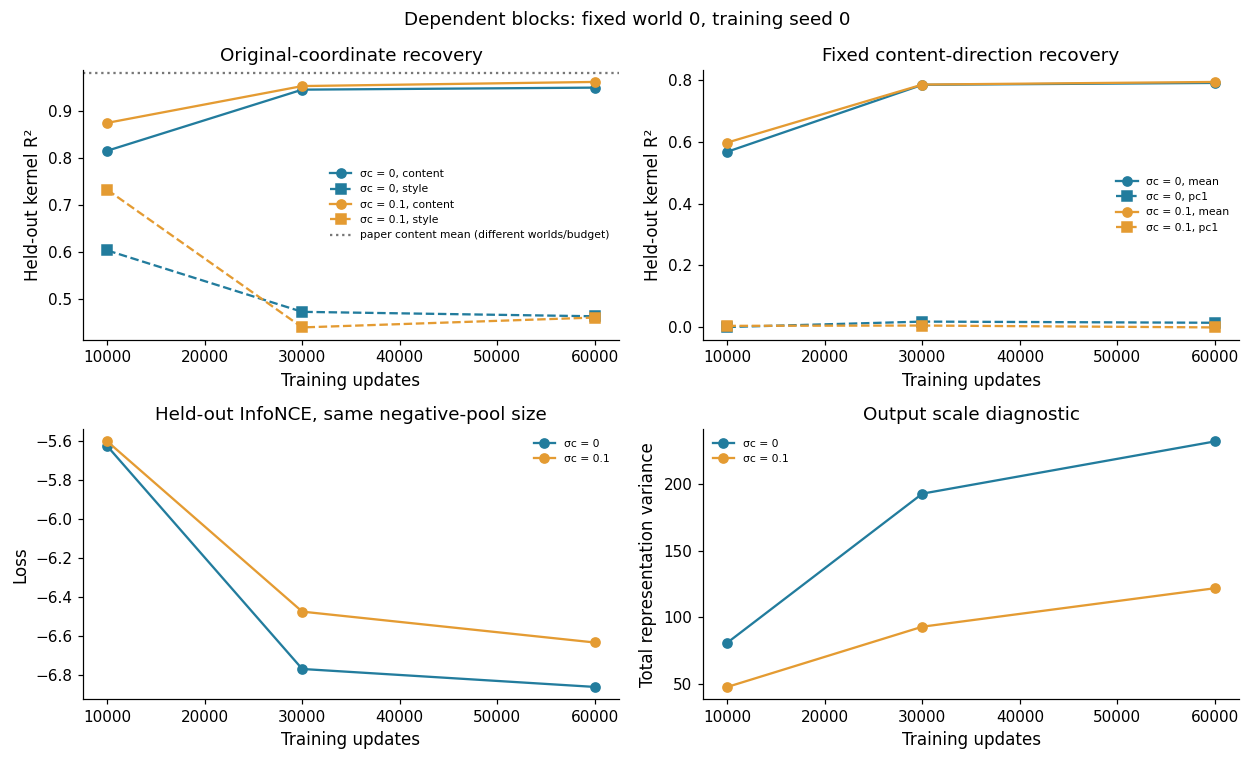

The paper line is contextual, not an expectation of exact numerical agreement at 60k.
Compare loss trajectories over time within each condition; the positive-pair distributions differ between σc conditions.
Output covariance diagnostics measure scale/geometry; they do not count recovered latent dimensions.
Main question: does invariant-content recovery catch up with longer training, especially for the weakest fixed direction?
If both content and style scores increase, describe better recoverability rather than cleaner separation.
Model/Adam/RNG checkpoints and encoded arrays are saved in: /content/extension_dependent_blocks_followup


In [19]:
# ADDED [11]: compare the SAME content targets at all budgets and both perturbation strengths.
if RUN_DEPENDENT_FOCUS:
    recovery_cols = ['content_linear', 'content_kernel', 'style_kernel', 'fixed_content_linear',
                     'fixed_content_kernel', 'weakest_content_linear', 'weakest_content_kernel', 'heldout_loss',
                     'output_total_variance', 'output_effective_rank']
    print('Focused results: one row per world, training seed, perturbation strength and budget.')
    display(focus.set_index(['world_seed', 'training_seed', 'sigma_c', 'updates'])[recovery_cols].round(4))
    print('Oracle probe reference uses all WHITENED true content as input. It is not a universal upper bound for learned representations.')
    display(focus_oracle[['world_seed', 'content_linear', 'content_kernel',
                          'fixed_content_linear', 'fixed_content_kernel', 'weakest_content_kernel']].round(4))

    fixed_cols = [f'fixed_kernel_pc{i+1}' for i in range(NC)]
    fixed_per_direction = focus[['world_seed', 'training_seed', 'sigma_c', 'updates'] + fixed_cols]
    fixed_per_direction.to_csv(FOCUS_DIR / 'fixed_content_direction_recovery.csv', index=False)
    print('Direct kernel probes for fixed unit-variance content directions; pc1 has least original population variance.')
    display(fixed_per_direction.set_index(['world_seed', 'training_seed', 'sigma_c', 'updates']).round(4))

    index = ['world_seed', 'training_seed', 'updates']
    invariant = focus[focus.sigma_c == 0.0].set_index(index).sort_index()
    perturbed = focus[focus.sigma_c == CONTENT_SIGMA].set_index(index).sort_index()
    assert invariant.index.equals(perturbed.index)
    paired_difference = perturbed[recovery_cols] - invariant[recovery_cols]
    paired_difference.to_csv(FOCUS_DIR / 'budget_paired_differences.csv')
    print('Paired differences: perturbed minus invariant at the same budget.')
    display(paired_difference.round(4))

    for world_seed in FOCUS_WORLD_SEEDS:
        for training_seed in FOCUS_TRAIN_SEEDS:
            subset = focus[(focus.world_seed == world_seed) & (focus.training_seed == training_seed)]
            fig, axes = plt.subplots(2, 2, figsize=(11.5, 7.0))
            for sigma_c, color in zip(FOCUS_CONTENT_SIGMAS, ['#227c9d', '#e49b32']):
                rows = subset[subset.sigma_c == sigma_c].sort_values('updates')
                label = f'σc = {sigma_c:g}'
                axes[0,0].plot(rows.updates, rows.content_kernel, marker='o', color=color, label=label + ', content')
                axes[0,0].plot(rows.updates, rows.style_kernel, marker='s', linestyle='--', color=color, label=label + ', style')
                axes[0,1].plot(rows.updates, rows.fixed_content_kernel, marker='o', color=color, label=label + ', mean')
                axes[0,1].plot(rows.updates, rows.weakest_content_kernel, marker='s', linestyle='--', color=color, label=label + ', pc1')
                axes[1,0].plot(rows.updates, rows.heldout_loss, marker='o', color=color, label=label)
                axes[1,1].plot(rows.updates, rows.output_total_variance, marker='o', color=color, label=label)
            axes[0,0].axhline(PAPER['dependent_blocks'][0], color='#777777', linestyle=':',
                              label='paper content mean (different worlds/budget)')
            axes[0,0].set(title='Original-coordinate recovery', ylabel='Held-out kernel R²')
            axes[0,1].set(title='Fixed content-direction recovery', ylabel='Held-out kernel R²')
            axes[1,0].set(title='Held-out InfoNCE, same negative-pool size', ylabel='Loss')
            axes[1,1].set(title='Output scale diagnostic', ylabel='Total representation variance')
            for ax in axes.flat:
                ax.set_xlabel('Training updates')
                ax.legend(frameon=False, fontsize=7)
            fig.suptitle(f'Dependent blocks: fixed world {world_seed}, training seed {training_seed}')
            fig.tight_layout()
            fig.savefig(FOCUS_DIR / f'budget_followup_world{world_seed}_train{training_seed}.png', dpi=150)
            plt.show()
    print('The paper line is contextual, not an expectation of exact numerical agreement at 60k.')
    print('Compare loss trajectories over time within each condition; the positive-pair distributions differ between σc conditions.')
    print('Output covariance diagnostics measure scale/geometry; they do not count recovered latent dimensions.')
    print('Main question: does invariant-content recovery catch up with longer training, especially for the weakest fixed direction?')
    print('If both content and style scores increase, describe better recoverability rather than cleaner separation.')
    print('Model/Adam/RNG checkpoints and encoded arrays are saved in:', FOCUS_DIR.resolve())

## Historical outputs from the supplied notebook — before the revision

The outputs below are retained for reference. They show the original perturbed-only
table and original independent sweep, **not the new four-setting paired controls**.
Their code source remains in the original notebook version. This static archive is
not recomputed by Run All. Use the revised result cells above for new comparisons
after rerunning.

### Historical results only — before paired controls

#### Original seed-zero sampled prices


  <div id="df-f58eec00-562f-4e38-9836-551bb4db190c" class="colab-df-container">
    <div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>c1</th>
      <th>c2</th>
      <th>c3</th>
      <th>c4</th>
      <th>c5</th>
      <th>s1</th>
      <th>s2</th>
      <th>s3</th>
      <th>s4</th>
      <th>s5</th>
    </tr>
    <tr>
      <th>scenario</th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>independent_all</th>
      <td>0.01</td>
      <td>0.01</td>
      <td>0.01</td>
      <td>0.01</td>
      <td>0.01</td>
      <td>0.997</td>
      <td>1.004</td>
      <td>1.016</td>
      <td>0.997</td>
      <td>1.009</td>
    </tr>
    <tr>
      <th>independent_partial</th>
      <td>0.01</td>
      <td>0.01</td>
      <td>0.01</td>
      <td>0.01</td>
      <td>0.01</td>
      <td>0.752</td>
      <td>0.744</td>
      <td>0.758</td>
      <td>0.744</td>
      <td>0.762</td>
    </tr>
    <tr>
      <th>dependent_blocks</th>
      <td>0.01</td>
      <td>0.01</td>
      <td>0.01</td>
      <td>0.01</td>
      <td>0.01</td>
      <td>1.813</td>
      <td>0.944</td>
      <td>0.838</td>
      <td>1.279</td>
      <td>2.233</td>
    </tr>
    <tr>
      <th>content_causes_style</th>
      <td>0.01</td>
      <td>0.01</td>
      <td>0.01</td>
      <td>0.01</td>
      <td>0.01</td>
      <td>0.228</td>
      <td>0.176</td>
      <td>0.317</td>
      <td>0.422</td>
      <td>0.842</td>
    </tr>
  </tbody>
</table>
</div>
    <div class="colab-df-buttons">

  <div class="colab-df-container">
    <button class="colab-df-convert" onclick="convertToInteractive('df-f58eec00-562f-4e38-9836-551bb4db190c')"
            title="Convert this dataframe to an interactive table."
            style="display:none;">

  <svg xmlns="http://www.w3.org/2000/svg" height="24px" viewBox="0 -960 960 960">
    <path d="M120-120v-720h720v720H120Zm60-500h600v-160H180v160Zm220 220h160v-160H400v160Zm0 220h160v-160H400v160ZM180-400h160v-160H180v160Zm440 0h160v-160H620v160ZM180-180h160v-160H180v160Zm440 0h160v-160H620v160Z"/>
  </svg>
    </button>

  <style>
    .colab-df-container {
      display:flex;
      gap: 12px;
    }

    .colab-df-convert {
      background-color: #E8F0FE;
      border: none;
      border-radius: 50%;
      cursor: pointer;
      display: none;
      fill: #1967D2;
      height: 32px;
      padding: 0 0 0 0;
      width: 32px;
    }

    .colab-df-convert:hover {
      background-color: #E2EBFA;
      box-shadow: 0px 1px 2px rgba(60, 64, 67, 0.3), 0px 1px 3px 1px rgba(60, 64, 67, 0.15);
      fill: #174EA6;
    }

    .colab-df-buttons div {
      margin-bottom: 4px;
    }

    [theme=dark] .colab-df-convert {
      background-color: #3B4455;
      fill: #D2E3FC;
    }

    [theme=dark] .colab-df-convert:hover {
      background-color: #434B5C;
      box-shadow: 0px 1px 3px 1px rgba(0, 0, 0, 0.15);
      filter: drop-shadow(0px 1px 2px rgba(0, 0, 0, 0.3));
      fill: #FFFFFF;
    }
  </style>

    <script>
      const buttonEl =
        document.querySelector('#df-f58eec00-562f-4e38-9836-551bb4db190c button.colab-df-convert');
      buttonEl.style.display =
        google.colab.kernel.accessAllowed ? 'block' : 'none';

      async function convertToInteractive(key) {
        const element = document.querySelector('#df-f58eec00-562f-4e38-9836-551bb4db190c');
        const dataTable =
          await google.colab.kernel.invokeFunction('convertToInteractive',
                                                    [key], {});
        if (!dataTable) return;

        const docLinkHtml = 'Like what you see? Visit the ' +
          '<a target="_blank" href=https://colab.research.google.com/notebooks/data_table.ipynb>data table notebook</a>'
          + ' to learn more about interactive tables.';
        element.innerHTML = '';
        dataTable['output_type'] = 'display_data';
        await google.colab.output.renderOutput(dataTable, element);
        const docLink = document.createElement('div');
        docLink.innerHTML = docLinkHtml;
        element.appendChild(docLink);
      }
    </script>
  </div>


    </div>
  </div>


#### Original perturbed-only table


  <div id="df-855579b6-7722-4f4e-9a7b-0e3364ceeea7" class="colab-df-container">
    <div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>p(chg.)</th>
      <th>Stat.</th>
      <th>Cau.</th>
      <th>Content c (leaky)</th>
      <th>Style s (leaky)</th>
      <th>Content c (paper)</th>
      <th>Style s (paper)</th>
      <th>seeds</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>independent_all</th>
      <td>1.00</td>
      <td>✗</td>
      <td>✗</td>
      <td>0.98 ± 0.00</td>
      <td>0.00 ± 0.00</td>
      <td>1.00 ± 0.00</td>
      <td>0.07 ± 0.00</td>
      <td>3</td>
    </tr>
    <tr>
      <th>independent_partial</th>
      <td>0.75</td>
      <td>✗</td>
      <td>✗</td>
      <td>0.98 ± 0.00</td>
      <td>0.00 ± 0.00</td>
      <td>1.00 ± 0.00</td>
      <td>0.06 ± 0.05</td>
      <td>3</td>
    </tr>
    <tr>
      <th>dependent_blocks</th>
      <td>0.75</td>
      <td>✓</td>
      <td>✗</td>
      <td>0.92 ± 0.04</td>
      <td>0.57 ± 0.30</td>
      <td>0.98 ± 0.03</td>
      <td>0.37 ± 0.05</td>
      <td>3</td>
    </tr>
    <tr>
      <th>content_causes_style</th>
      <td>0.75</td>
      <td>✓</td>
      <td>✓</td>
      <td>0.92 ± 0.03</td>
      <td>0.88 ± 0.06</td>
      <td>0.99 ± 0.01</td>
      <td>0.80 ± 0.08</td>
      <td>3</td>
    </tr>
  </tbody>
</table>
</div>
    <div class="colab-df-buttons">

  <div class="colab-df-container">
    <button class="colab-df-convert" onclick="convertToInteractive('df-855579b6-7722-4f4e-9a7b-0e3364ceeea7')"
            title="Convert this dataframe to an interactive table."
            style="display:none;">

  <svg xmlns="http://www.w3.org/2000/svg" height="24px" viewBox="0 -960 960 960">
    <path d="M120-120v-720h720v720H120Zm60-500h600v-160H180v160Zm220 220h160v-160H400v160Zm0 220h160v-160H400v160ZM180-400h160v-160H180v160Zm440 0h160v-160H620v160ZM180-180h160v-160H180v160Zm440 0h160v-160H620v160Z"/>
  </svg>
    </button>

  <style>
    .colab-df-container {
      display:flex;
      gap: 12px;
    }

    .colab-df-convert {
      background-color: #E8F0FE;
      border: none;
      border-radius: 50%;
      cursor: pointer;
      display: none;
      fill: #1967D2;
      height: 32px;
      padding: 0 0 0 0;
      width: 32px;
    }

    .colab-df-convert:hover {
      background-color: #E2EBFA;
      box-shadow: 0px 1px 2px rgba(60, 64, 67, 0.3), 0px 1px 3px 1px rgba(60, 64, 67, 0.15);
      fill: #174EA6;
    }

    .colab-df-buttons div {
      margin-bottom: 4px;
    }

    [theme=dark] .colab-df-convert {
      background-color: #3B4455;
      fill: #D2E3FC;
    }

    [theme=dark] .colab-df-convert:hover {
      background-color: #434B5C;
      box-shadow: 0px 1px 3px 1px rgba(0, 0, 0, 0.15);
      filter: drop-shadow(0px 1px 2px rgba(0, 0, 0, 0.3));
      fill: #FFFFFF;
    }
  </style>

    <script>
      const buttonEl =
        document.querySelector('#df-855579b6-7722-4f4e-9a7b-0e3364ceeea7 button.colab-df-convert');
      buttonEl.style.display =
        google.colab.kernel.accessAllowed ? 'block' : 'none';

      async function convertToInteractive(key) {
        const element = document.querySelector('#df-855579b6-7722-4f4e-9a7b-0e3364ceeea7');
        const dataTable =
          await google.colab.kernel.invokeFunction('convertToInteractive',
                                                    [key], {});
        if (!dataTable) return;

        const docLinkHtml = 'Like what you see? Visit the ' +
          '<a target="_blank" href=https://colab.research.google.com/notebooks/data_table.ipynb>data table notebook</a>'
          + ' to learn more about interactive tables.';
        element.innerHTML = '';
        dataTable['output_type'] = 'display_data';
        await google.colab.output.renderOutput(dataTable, element);
        const docLink = document.createElement('div');
        docLink.innerHTML = docLinkHtml;
        element.appendChild(docLink);
      }
    </script>
  </div>


  <div id="id_0a80be55-3669-43be-8fd6-773cbdf034fc">
    <style>
      .colab-df-generate {
        background-color: #E8F0FE;
        border: none;
        border-radius: 50%;
        cursor: pointer;
        display: none;
        fill: #1967D2;
        height: 32px;
        padding: 0 0 0 0;
        width: 32px;
      }

      .colab-df-generate:hover {
        background-color: #E2EBFA;
        box-shadow: 0px 1px 2px rgba(60, 64, 67, 0.3), 0px 1px 3px 1px rgba(60, 64, 67, 0.15);
        fill: #174EA6;
      }

      [theme=dark] .colab-df-generate {
        background-color: #3B4455;
        fill: #D2E3FC;
      }

      [theme=dark] .colab-df-generate:hover {
        background-color: #434B5C;
        box-shadow: 0px 1px 3px 1px rgba(0, 0, 0, 0.15);
        filter: drop-shadow(0px 1px 2px rgba(0, 0, 0, 0.3));
        fill: #FFFFFF;
      }
    </style>
    <button class="colab-df-generate" onclick="generateWithVariable('leaky_table')"
            title="Generate code using this dataframe."
            style="display:none;">

  <svg xmlns="http://www.w3.org/2000/svg" height="24px"viewBox="0 0 24 24"
       width="24px">
    <path d="M7,19H8.4L18.45,9,17,7.55,7,17.6ZM5,21V16.75L18.45,3.32a2,2,0,0,1,2.83,0l1.4,1.43a1.91,1.91,0,0,1,.58,1.4,1.91,1.91,0,0,1-.58,1.4L9.25,21ZM18.45,9,17,7.55Zm-12,3A5.31,5.31,0,0,0,4.9,8.1,5.31,5.31,0,0,0,1,6.5,5.31,5.31,0,0,0,4.9,4.9,5.31,5.31,0,0,0,6.5,1,5.31,5.31,0,0,0,8.1,4.9,5.31,5.31,0,0,0,12,6.5,5.46,5.46,0,0,0,6.5,12Z"/>
  </svg>
    </button>
    <script>
      (() => {
      const buttonEl =
        document.querySelector('#id_0a80be55-3669-43be-8fd6-773cbdf034fc button.colab-df-generate');
      buttonEl.style.display =
        google.colab.kernel.accessAllowed ? 'block' : 'none';

      buttonEl.onclick = () => {
        google.colab.notebook.generateWithVariable('leaky_table');
      }
      })();
    </script>
  </div>

    </div>
  </div>


#### Original per-coordinate means


  <div id="df-be3c6e83-4235-45e4-aa4d-3526eaa3f171" class="colab-df-container">
    <div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>c1</th>
      <th>c2</th>
      <th>c3</th>
      <th>c4</th>
      <th>c5</th>
      <th>s1</th>
      <th>s2</th>
      <th>s3</th>
      <th>s4</th>
      <th>s5</th>
    </tr>
    <tr>
      <th>scenario</th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
      <th></th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>independent_all</th>
      <td>0.98</td>
      <td>0.98</td>
      <td>0.98</td>
      <td>0.98</td>
      <td>0.98</td>
      <td>0.00</td>
      <td>0.00</td>
      <td>0.00</td>
      <td>0.00</td>
      <td>-0.00</td>
    </tr>
    <tr>
      <th>independent_partial</th>
      <td>0.98</td>
      <td>0.98</td>
      <td>0.98</td>
      <td>0.98</td>
      <td>0.98</td>
      <td>0.00</td>
      <td>-0.00</td>
      <td>0.00</td>
      <td>-0.00</td>
      <td>-0.00</td>
    </tr>
    <tr>
      <th>dependent_blocks</th>
      <td>0.93</td>
      <td>0.85</td>
      <td>0.95</td>
      <td>0.96</td>
      <td>0.90</td>
      <td>0.55</td>
      <td>0.29</td>
      <td>0.60</td>
      <td>0.57</td>
      <td>0.84</td>
    </tr>
    <tr>
      <th>content_causes_style</th>
      <td>0.96</td>
      <td>0.85</td>
      <td>0.94</td>
      <td>0.97</td>
      <td>0.87</td>
      <td>0.95</td>
      <td>0.78</td>
      <td>0.94</td>
      <td>0.85</td>
      <td>0.88</td>
    </tr>
  </tbody>
</table>
</div>
    <div class="colab-df-buttons">

  <div class="colab-df-container">
    <button class="colab-df-convert" onclick="convertToInteractive('df-be3c6e83-4235-45e4-aa4d-3526eaa3f171')"
            title="Convert this dataframe to an interactive table."
            style="display:none;">

  <svg xmlns="http://www.w3.org/2000/svg" height="24px" viewBox="0 -960 960 960">
    <path d="M120-120v-720h720v720H120Zm60-500h600v-160H180v160Zm220 220h160v-160H400v160Zm0 220h160v-160H400v160ZM180-400h160v-160H180v160Zm440 0h160v-160H620v160ZM180-180h160v-160H180v160Zm440 0h160v-160H620v160Z"/>
  </svg>
    </button>

  <style>
    .colab-df-container {
      display:flex;
      gap: 12px;
    }

    .colab-df-convert {
      background-color: #E8F0FE;
      border: none;
      border-radius: 50%;
      cursor: pointer;
      display: none;
      fill: #1967D2;
      height: 32px;
      padding: 0 0 0 0;
      width: 32px;
    }

    .colab-df-convert:hover {
      background-color: #E2EBFA;
      box-shadow: 0px 1px 2px rgba(60, 64, 67, 0.3), 0px 1px 3px 1px rgba(60, 64, 67, 0.15);
      fill: #174EA6;
    }

    .colab-df-buttons div {
      margin-bottom: 4px;
    }

    [theme=dark] .colab-df-convert {
      background-color: #3B4455;
      fill: #D2E3FC;
    }

    [theme=dark] .colab-df-convert:hover {
      background-color: #434B5C;
      box-shadow: 0px 1px 3px 1px rgba(0, 0, 0, 0.15);
      filter: drop-shadow(0px 1px 2px rgba(0, 0, 0, 0.3));
      fill: #FFFFFF;
    }
  </style>

    <script>
      const buttonEl =
        document.querySelector('#df-be3c6e83-4235-45e4-aa4d-3526eaa3f171 button.colab-df-convert');
      buttonEl.style.display =
        google.colab.kernel.accessAllowed ? 'block' : 'none';

      async function convertToInteractive(key) {
        const element = document.querySelector('#df-be3c6e83-4235-45e4-aa4d-3526eaa3f171');
        const dataTable =
          await google.colab.kernel.invokeFunction('convertToInteractive',
                                                    [key], {});
        if (!dataTable) return;

        const docLinkHtml = 'Like what you see? Visit the ' +
          '<a target="_blank" href=https://colab.research.google.com/notebooks/data_table.ipynb>data table notebook</a>'
          + ' to learn more about interactive tables.';
        element.innerHTML = '';
        dataTable['output_type'] = 'display_data';
        await google.colab.output.renderOutput(dataTable, element);
        const docLink = document.createElement('div');
        docLink.innerHTML = docLinkHtml;
        element.appendChild(docLink);
      }
    </script>
  </div>


    </div>
  </div>


#### Original independent one-seed sweep


  <div id="df-2aa8c4b0-0ac3-4aed-891c-9cadd10a1aa9" class="colab-df-container">
    <div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>sigma_c</th>
      <th>r_c</th>
      <th>content_nonlinear</th>
      <th>style_nonlinear</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>0</th>
      <td>0.0</td>
      <td>0.00</td>
      <td>0.970</td>
      <td>0.007</td>
    </tr>
    <tr>
      <th>1</th>
      <td>0.1</td>
      <td>0.01</td>
      <td>0.980</td>
      <td>-0.000</td>
    </tr>
    <tr>
      <th>2</th>
      <td>0.3</td>
      <td>0.09</td>
      <td>0.984</td>
      <td>0.000</td>
    </tr>
    <tr>
      <th>3</th>
      <td>0.6</td>
      <td>0.36</td>
      <td>0.954</td>
      <td>0.007</td>
    </tr>
    <tr>
      <th>4</th>
      <td>1.0</td>
      <td>1.00</td>
      <td>0.440</td>
      <td>0.462</td>
    </tr>
  </tbody>
</table>
</div>
    <div class="colab-df-buttons">

  <div class="colab-df-container">
    <button class="colab-df-convert" onclick="convertToInteractive('df-2aa8c4b0-0ac3-4aed-891c-9cadd10a1aa9')"
            title="Convert this dataframe to an interactive table."
            style="display:none;">

  <svg xmlns="http://www.w3.org/2000/svg" height="24px" viewBox="0 -960 960 960">
    <path d="M120-120v-720h720v720H120Zm60-500h600v-160H180v160Zm220 220h160v-160H400v160Zm0 220h160v-160H400v160ZM180-400h160v-160H180v160Zm440 0h160v-160H620v160ZM180-180h160v-160H180v160Zm440 0h160v-160H620v160Z"/>
  </svg>
    </button>

  <style>
    .colab-df-container {
      display:flex;
      gap: 12px;
    }

    .colab-df-convert {
      background-color: #E8F0FE;
      border: none;
      border-radius: 50%;
      cursor: pointer;
      display: none;
      fill: #1967D2;
      height: 32px;
      padding: 0 0 0 0;
      width: 32px;
    }

    .colab-df-convert:hover {
      background-color: #E2EBFA;
      box-shadow: 0px 1px 2px rgba(60, 64, 67, 0.3), 0px 1px 3px 1px rgba(60, 64, 67, 0.15);
      fill: #174EA6;
    }

    .colab-df-buttons div {
      margin-bottom: 4px;
    }

    [theme=dark] .colab-df-convert {
      background-color: #3B4455;
      fill: #D2E3FC;
    }

    [theme=dark] .colab-df-convert:hover {
      background-color: #434B5C;
      box-shadow: 0px 1px 3px 1px rgba(0, 0, 0, 0.15);
      filter: drop-shadow(0px 1px 2px rgba(0, 0, 0, 0.3));
      fill: #FFFFFF;
    }
  </style>

    <script>
      const buttonEl =
        document.querySelector('#df-2aa8c4b0-0ac3-4aed-891c-9cadd10a1aa9 button.colab-df-convert');
      buttonEl.style.display =
        google.colab.kernel.accessAllowed ? 'block' : 'none';

      async function convertToInteractive(key) {
        const element = document.querySelector('#df-2aa8c4b0-0ac3-4aed-891c-9cadd10a1aa9');
        const dataTable =
          await google.colab.kernel.invokeFunction('convertToInteractive',
                                                    [key], {});
        if (!dataTable) return;

        const docLinkHtml = 'Like what you see? Visit the ' +
          '<a target="_blank" href=https://colab.research.google.com/notebooks/data_table.ipynb>data table notebook</a>'
          + ' to learn more about interactive tables.';
        element.innerHTML = '';
        dataTable['output_type'] = 'display_data';
        await google.colab.output.renderOutput(dataTable, element);
        const docLink = document.createElement('div');
        docLink.innerHTML = docLinkHtml;
        element.appendChild(docLink);
      }
    </script>
  </div>


    </div>
  </div>


![Historical independent sweep](attachment:historical_sweep.png)